# **Predicción del puntaje global del Saber 11 (2025)**

**Pregunta:** ¿Se puede predecir el puntaje global del Saber 11 2025 a partir de variables socioeconómicas y escolares, y qué tan bien generaliza el modelo para Santander y para distintos tipos de colegio?

**Objetivo general:** desarrollar y comparar modelos de machine learning y deep learning que predigan el puntaje global del Saber 11 2025 a partir de variables socioeconómicas y del entorno escolar, y evaluar su generalización por región y tipo de colegio.

**Objetivos específicos:**
1. Analizar la relación entre las variables y el puntaje, con un tratamiento adecuado de los datos faltantes, y seleccionar las variables con un método formal.
2. Comparar el desempeño del modelo y la importancia de las variables entre Santander y el resto del país.
3. Evaluar si el error del modelo y la importancia de las variables cambian entre colegios oficiales y no oficiales, y entre zona urbana y rural.

**Tipo de problema:** regresión, porque el puntaje global es un número continuo entre 0 y 500.:

## **Preparación y limpieza de datos**


Nota: Se realizó de nuevo una exploración de los datos debido al ajuste propuesto en la primera entrega de utilizar únicamente los datos del año 2025

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_theme(style="whitegrid", palette="mako", font_scale=1.1)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Georgia", "DejaVu Serif", "Times New Roman"]

color_acento = "#2c7fb8"
color_secundario = "#d95f0e"

### **Carga y filtro de los datos**

Se usa el dataset "Resultados ICFES 2019-2025" de Kaggle. Como el archivo es muy grande (3.37 GB), se lee por bloques y solo se conservan los dos periodos de 2025 (20251 y 20252), siguiendo la sugerencia del profesor.

**Variables cargadas:** el puntaje global (variable objetivo), las variables del hogar, del colegio y del estudiante que se usarán como predictoras, el periodo y el departamento del colegio (para evaluar el modelo por región).

**No se cargan:**
- Los puntajes por área, percentiles y niveles de desempeño, porque se calculan a partir del mismo examen. Usarlos sería filtración.
- Los índices socioeconómicos del ICFES (INSE/NSE), porque resumen varias variables en un solo número y harían más difícil interpretar qué factores influyen en el puntaje.

**Ajustes:**
- Se corrigen los caracteres mal codificados del texto (tildes que aparecen como símbolos extraños).
- Se conservan solo los inscritos como `ESTUDIANTE`, es decir, quienes presentan el examen desde un colegio. Los inscritos como `INDIVIDUAL` (92,717) no tienen información del colegio, y el proyecto estudia la relación entre el colegio y el puntaje. Después del filtro quedan **569,174 estudiantes**, y casi desaparecen los vacíos de las variables del colegio.

In [ ]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("esgaritus/resultados-icfes-2019-2025")
archivo = os.path.join(path, "df_icfes_historico (full).csv")

cols = [
    "punt_global", "periodo",
    "estu_estudiante", "cole_depto_ubicacion",
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_tienecomputador",
    "fami_situacioneconomica",
    "fami_personashogar", "fami_cuartoshogar",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter",
    "cole_jornada", "cole_calendario",
    "estu_genero", "estu_horassemanatrabaja",
]

# Conservar solo 2025
PERIODOS_2025 = {20251, 20252}

bloques = []
for chunk in pd.read_csv(archivo, usecols=cols, chunksize=500_000, low_memory=False):
    bloques.append(chunk[chunk["periodo"].isin(PERIODOS_2025)])
df = pd.concat(bloques, ignore_index=True)
del bloques

print("Periodos cargados:", sorted(df["periodo"].unique()))
print("Filas 2025 (antes de filtrar estudiantes):", df.shape[0])

#Corrección letras raras
def correccion_letras(texto):
    if isinstance(texto, str):
        try:
            return texto.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto

cols_texto = df.select_dtypes(include="object").columns
for col in cols_texto:
    unicos = df[col].dropna().unique()
    df[col] = df[col].map({u: correccion_letras(u) for u in unicos})

# Dejar solo estudiantes
print("\nValores de estu_estudiante:")
print(df["estu_estudiante"].value_counts(dropna=False))

es_estudiante = df["estu_estudiante"].astype(str).str.strip().str.upper() == "ESTUDIANTE"
print(f"\nSe conservan {es_estudiante.sum():,} filas "
      f"({es_estudiante.mean():.1%}); se eliminan {(~es_estudiante).sum():,}")

df = df[es_estudiante].drop(columns="estu_estudiante").reset_index(drop=True)

# Los nulos eran causados por datos de los que no son estudiantes?
cols_cole = ["cole_naturaleza", "cole_area_ubicacion", "cole_jornada",
             "cole_caracter", "cole_calendario", "cole_depto_ubicacion"]
print("\n% de nulos en cole_* después del filtro:")
print((df[cols_cole].isnull().mean() * 100).round(2))

print("\nFilas finales (2025, solo estudiantes):", df.shape[0])
print("Distribución por periodo:")
print(df["periodo"].value_counts().sort_index())
df.head(10)

100%|██████████| 544M/544M [00:05<00:00, 99.3MB/s]

Extracting files...


Periodos cargados: [np.int64(20251), np.int64(20252)]
Filas 2025 (antes de filtrar estudiantes): 661891

Valores de estu_estudiante:
estu_estudiante
ESTUDIANTE    569174
INDIVIDUAL     92717
Name: count, dtype: int64

Se conservan 569,174 filas (86.0%); se eliminan 92,717

% de nulos en cole_* después del filtro:
cole_naturaleza         0.00
cole_area_ubicacion     0.00
cole_jornada            0.02
cole_caracter           5.14
cole_calendario         0.02
cole_depto_ubicacion    0.00
dtype: float64

Filas finales (2025, solo estudiantes): 569174
Distribución por periodo:
periodo
20251     21793
20252    547381
Name: count, dtype: int64


,periodo,cole_area_ubicacion,cole_calendario,cole_caracter,cole_depto_ubicacion,cole_jornada,cole_naturaleza,estu_genero,estu_horassemanatrabaja,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_numlibros,fami_personashogar,fami_situacioneconomica,fami_tienecomputador,fami_tieneinternet,punt_global
0,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,M,0,Cuatro,Postgrado,Postgrado,Estrato 6,MÁS DE 100 LIBROS,3 a 4,Mejor,Si,Si,358
1,20251,URBANO,A,ACADÉMICO,SANTANDER,UNICA,NO OFICIAL,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,344
2,20251,URBANA,B,NaN,BOGOTÁ,UNICA,NO OFICIAL,F,0,Cuatro,Educación profesional completa,Educación profesional incompleta,Estrato 3,11 A 25 LIBROS,3 a 4,Mejor,Si,Si,345
3,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,323
4,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,307
5,20251,URBANA,B,TÉCNICO/ACADÉMICO,VALLE,MAÑANA,NO OFICIAL,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,300
6,20251,URBANO,A,ACADÉMICO,BOGOTÁ,MAÑANA,NO OFICIAL,F,Menos de 10 horas,Uno,NaN,NaN,NaN,NaN,5 a 6,Igual,Si,NaN,179
7,20251,RURAL,B,ACADÉMICO,CUNDINAMARCA,COMPLETA,NO OFICIAL,M,0,Tres,Educación profesional completa,Educación profesional completa,Estrato 5,26 A 100 LIBROS,3 a 4,Igual,Si,Si,323
8,20251,URBANO,A,NaN,NARIÑO,SABATINA,NO OFICIAL,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206
9,20251,URBANA,B,TÉCNICO/ACADÉMICO,VALLE,TARDE,NO OFICIAL,M,0,Cuatro,No sabe,Educación profesional completa,NaN,11 A 25 LIBROS,7 a 8,Igual,Si,Si,319


### **Diagnóstico de valores faltantes**

Antes de decidir qué hacer con los valores faltantes, se revisa cuántos hay en cada variable y si los estudiantes que no responden se diferencian de los que sí.

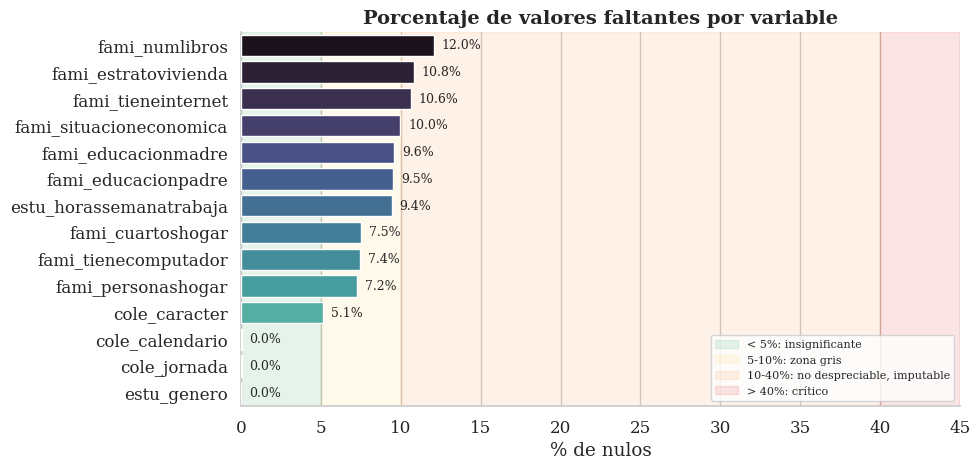

In [ ]:
pct_nulos = (df.isnull().mean() * 100).sort_values(ascending=False)
pct_nulos = pct_nulos[pct_nulos > 0]

fig, ax = plt.subplots(figsize=(10, max(4, len(pct_nulos)*0.35)))

ax.axvspan(0, 5, color="#2ca25f", alpha=0.12, label="< 5%: insignificante")
ax.axvspan(5, 10, color="#fed976", alpha=0.15, label="5-10%: zona gris")
ax.axvspan(10, 40, color="#fd8d3c", alpha=0.12, label="10-40%: no despreciable, imputable")
ax.axvspan(40, max(45, pct_nulos.max()+5), color="#de2d26", alpha=0.12, label="> 40%: crítico")

sns.barplot(x=pct_nulos.values, y=pct_nulos.index, hue=pct_nulos.index,
            palette="mako", legend=False, ax=ax, zorder=3)

for i, v in enumerate(pct_nulos.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9, zorder=4)

ax.set_title("Porcentaje de valores faltantes por variable", fontsize=14, fontweight="bold")
ax.set_xlabel("% de nulos")
ax.set_ylabel("")
ax.set_xlim(0, max(45, pct_nulos.max()+8))
ax.legend(frameon=True, loc="lower right", fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Revisar nulos
cols_fami = [
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_tienecomputador",
    "fami_situacioneconomica", "fami_personashogar", "fami_cuartoshogar",
]
cols_revisar = cols_fami + ["estu_horassemanatrabaja", "cole_caracter"]

faltantes = df[cols_revisar].isnull()

# Nulos por fila
n_falt_fami = faltantes[cols_fami].sum(axis=1)
print("Número de variables familiares faltantes por fila:")
print(n_falt_fami.value_counts().sort_index().to_string())
print(f"\nFilas sin NINGUNA variable familiar: {(n_falt_fami == len(cols_fami)).mean():.2%}")

# Estadísticos con faltantes
std_global = df["punt_global"].std()
filas = []
for col in cols_revisar:
    falta = faltantes[col]
    media_falta = df.loc[falta, "punt_global"].mean()
    media_hay = df.loc[~falta, "punt_global"].mean()
    filas.append({
        "variable": col,
        "% faltante": round(falta.mean() * 100, 2),
        "media con faltante": round(media_falta, 1),
        "media sin faltante": round(media_hay, 1),
        "diferencia": round(media_falta - media_hay, 1),
        "d de Cohen": round((media_falta - media_hay) / std_global, 2),
    })

diagnostico = pd.DataFrame(filas).sort_values("d de Cohen")
diagnostico

Número de variables familiares faltantes por fila:
0    456314
1     34538
2      8375
3       848
4     14847
5     28154
6      1916
7       383
8       318
9     23481

Filas sin NINGUNA variable familiar: 4.13%


,variable,% faltante,media con faltante,media sin faltante,diferencia,d de Cohen
3,fami_numlibros,12.04,237.5,259.4,-21.9,-0.40
0,fami_estratovivienda,10.81,239.2,258.9,-19.7,-0.36
1,fami_educacionmadre,9.59,238.7,258.7,-19.9,-0.36
2,fami_educacionpadre,9.53,238.8,258.7,-19.8,-0.36
4,fami_tieneinternet,10.60,242.3,258.5,-16.2,-0.29
10,cole_caracter,5.14,242.9,257.5,-14.6,-0.27
5,fami_tienecomputador,7.43,248.3,257.4,-9.1,-0.17
7,fami_personashogar,7.25,249.5,257.3,-7.9,-0.14
8,fami_cuartoshogar,7.49,249.7,257.3,-7.6,-0.14
6,fami_situacioneconomica,9.97,252.3,257.3,-4.9,-0.09


**Resultados del diagnóstico:**

- **Los faltantes van en bloque:** muchos estudiantes no responden varias preguntas del hogar a la vez, y el 4.13% no responde ninguna.
- **Quienes no responden sacan menos puntaje:** hasta 22 puntos menos en número de libros, estrato y educación de los padres. Para medir el tamaño de la diferencia se usa la d de Cohen, que llega hasta −0.40, un efecto entre pequeño y mediano.

**Conclusión:** los faltantes no son completamente al azar, porque no responder está relacionado con el puntaje.

**Decisión:**
- **No se eliminan filas.** Ni siquiera el 4.13% sin información del hogar, porque son estudiantes con puntajes más bajos y eliminarlos sesgaría los datos hacia puntajes altos.
- **"No reporta" como categoría propia.** No responder es información en sí misma, así que en lugar de inventar un valor, el vacío se convierte en la respuesta "No reporta".

### **Categoría "No reporta"**

Siguiendo la decisión anterior, los vacíos de todas las variables categóricas se reemplazan por "No reporta". Es una regla fija, no una estadística de los datos, por lo que puede hacerse antes de separar entrenamiento y prueba sin causar filtración.

In [ ]:
# Categoría "No reporta" para nulos

cols_categoricas = [
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_tienecomputador",
    "fami_situacioneconomica", "fami_personashogar", "fami_cuartoshogar",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter",
    "cole_jornada", "cole_calendario",
    "estu_genero", "estu_horassemanatrabaja",
]

for col in cols_categoricas:
    df[col] = df[col].fillna("No reporta")

df[cols_categoricas].isnull().sum()

,0
fami_estratovivienda,0
fami_educacionmadre,0
fami_educacionpadre,0
fami_numlibros,0
fami_tieneinternet,0
fami_tienecomputador,0
fami_situacioneconomica,0
fami_personashogar,0
fami_cuartoshogar,0
cole_naturaleza,0


### **Revisión de categorías**

In [ ]:
for col in cols_categoricas + ["periodo"]:
    print(f"\n")
    print(df[col].value_counts().to_string())



fami_estratovivienda
Estrato 2      168621
Estrato 3      126812
Estrato 1      125310
No reporta      61518
Estrato 4       39356
Sin Estrato     27269
Estrato 5       13096
Estrato 6        7192


fami_educacionmadre
Secundaria (Bachillerato) completa      146371
Educación profesional completa           73924
Secundaria (Bachillerato) incompleta     65384
No reporta                               54560
Técnica o tecnológica completa           54350
Primaria incompleta                      52487
Primaria completa                        33297
Técnica o tecnológica incompleta         19295
No sabe                                  19046
Ninguno                                  17252
Educación profesional incompleta         17000
Postgrado                                14755
No Aplica                                 1453


fami_educacionpadre
Secundaria (Bachillerato) completa      130698
Secundaria (Bachillerato) incompleta     74362
Primaria incompleta                      69830
Educa

In [ ]:
# Unificar categoría duplicada
df["cole_area_ubicacion"] = df["cole_area_ubicacion"].replace({"URBANO": "URBANA"})

In [ ]:
df.head()

,periodo,cole_area_ubicacion,cole_calendario,cole_caracter,cole_depto_ubicacion,cole_jornada,cole_naturaleza,estu_genero,estu_horassemanatrabaja,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_numlibros,fami_personashogar,fami_situacioneconomica,fami_tienecomputador,fami_tieneinternet,punt_global
0,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,M,0,Cuatro,Postgrado,Postgrado,Estrato 6,MÁS DE 100 LIBROS,3 a 4,Mejor,Si,Si,358
1,20251,URBANA,A,ACADÉMICO,SANTANDER,UNICA,NO OFICIAL,M,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,344
2,20251,URBANA,B,No reporta,BOGOTÁ,UNICA,NO OFICIAL,F,0,Cuatro,Educación profesional completa,Educación profesional incompleta,Estrato 3,11 A 25 LIBROS,3 a 4,Mejor,Si,Si,345
3,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,M,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,323
4,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,F,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,No reporta,307


## **1. Encoding de variables**

Los modelos solo trabajan con números, así que cada variable se convierte según su tipo:

- **Ordinales** (estrato, educación de la madre y del padre, libros, situación económica, personas, cuartos, horas de trabajo): cada respuesta se reemplaza por un número que respeta su orden (por ejemplo, estrato 1 → 1, estrato 2 → 2).

- **Respuestas fuera de escala** ("No reporta", "No sabe", "Sin Estrato", "No Aplica"): no corresponden a ningún nivel de la escala, así que el número queda vacío (NaN) en lugar de inventar un nivel. Para no perder qué respondió el estudiante, se crea una variable indicadora (0/1) por cada una de estas respuestas, ya que cada una se asocia a puntajes distintos (ver la tabla al final de este paso). La excepción es "No Aplica" en la educación de los padres, que se representa con `presencia_padres`.

- **`presencia_padres`** (variable derivada): indica si el padre, la madre o ambos fueron reportados como "No Aplica" en educación. Reemplaza a los indicadores "No Aplica" de cada padre porque contiene la misma información y, además, distingue el caso en que faltan ambos.

- **`hacinamiento`** (variable derivada): personas por cuarto. Resume en un solo valor el tamaño del hogar frente al espacio disponible.

- **Escalado de las ordinales:** cada nivel se lleva a un valor entre 0 y 1 usando el mínimo y el máximo de su escala (por ejemplo, estrato 1 → 0 y estrato 6 → 1). El mínimo y el máximo vienen de las opciones del cuestionario, no de los datos. Así todas las columnas del modelo quedan en la misma escala que las variables 0/1, lo que necesitan la Regresión Lineal, el SVM y la red neuronal. A los árboles no les afecta.

- **Nominales** (internet, computador, naturaleza, área, carácter, jornada, calendario, género, periodo y `presencia_padres`): no tienen orden, así que se aplica **one-hot**: una columna 0/1 por categoría. En cada variable se elimina una categoría (`drop_first`), que queda como referencia para evitar redundancias.

- **Departamento:** no entra al modelo. El objetivo 2 busca saber si las relaciones entre las variables socioeconómicas y escolares y el puntaje se cumplen igual en Santander que en el resto del país. Si el modelo conociera el departamento, compensaría las diferencias regionales y no se podrían detectar. Solo se usa para evaluar el modelo por región.

In [ ]:
# Asignar un número a cada respuesta según su orden
niveles_estrato = {f"Estrato {i}": i for i in range(1, 7)}

niveles_educacion = {
    "Ninguno": 0,
    "Primaria incompleta": 1, "Primaria completa": 2,
    "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
    "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
    "Educación profesional incompleta": 7, "Educación profesional completa": 8,
    "Postgrado": 9,
}

niveles_libros = {"0 A 10 LIBROS": 0, "11 A 25 LIBROS": 1,
                  "26 A 100 LIBROS": 2, "MÁS DE 100 LIBROS": 3}

niveles_situacion = {"Peor": 0, "Igual": 1, "Mejor": 2}

niveles_personas = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9}

niveles_cuartos = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}

niveles_horas = {"0": 0, "Menos de 10 horas": 1, "Entre 11 y 20 horas": 2,
                 "Entre 21 y 30 horas": 3, "Más de 30 horas": 4}

# Variables ordinales con sus niveles y sus respuestas fuera de escala
variables_ordinales = {
    "fami_estratovivienda":    (niveles_estrato,   ["No reporta", "Sin Estrato"]),
    "fami_educacionmadre":     (niveles_educacion, ["No reporta", "No sabe", "No Aplica"]),
    "fami_educacionpadre":     (niveles_educacion, ["No reporta", "No sabe", "No Aplica"]),
    "fami_numlibros":          (niveles_libros,    ["No reporta"]),
    "fami_situacioneconomica": (niveles_situacion, ["No reporta"]),
    "fami_personashogar":      (niveles_personas,  ["No reporta"]),
    "fami_cuartoshogar":       (niveles_cuartos,   ["No reporta"]),
    "estu_horassemanatrabaja": (niveles_horas,     ["No reporta"]),
}

# No crear variable indicadora para "No Aplica" porque ya lo dice presencia_padres
SIN_INDICADORA = {"No Aplica"}

def nombre_indicadora(variable, respuesta):
    return f"{variable}__{respuesta.lower().replace(' ', '_')}"

# Pasar cada variable ordinal a niveles y crear sus variables indicadoras
indicadoras = {}

for variable, (niveles, fuera_escala) in variables_ordinales.items():
    # Las respuestas fuera de escala quedan como NaN en la nueva columna
    df[f"{variable}_ord"] = df[variable].map(niveles)

    # Una variable indicadora 0/1 por cada respuesta fuera de escala
    indicadoras[variable] = []
    for respuesta in fuera_escala:
        if respuesta in SIN_INDICADORA:
            continue
        columna = nombre_indicadora(variable, respuesta)
        df[columna] = (df[variable] == respuesta).astype(int)
        indicadoras[variable].append(columna)

# Variables derivadas
# Presencia de los padres según "No Aplica" en educación
madre_no_aplica = df["fami_educacionmadre"] == "No Aplica"
padre_no_aplica = df["fami_educacionpadre"] == "No Aplica"
df["presencia_padres"] = np.select(
    [madre_no_aplica & padre_no_aplica, padre_no_aplica, madre_no_aplica],
    ["Ambos no aplica", "Padre no aplica", "Madre no aplica"],
    default="Sin ausencia reportada",
)

# Hacinamiento: personas por cuarto (NaN si falta alguno de los dos)
df["hacinamiento"] = df["fami_personashogar_ord"] / df["fami_cuartoshogar_ord"]

# Escalar las ordinales entre 0 y 1 con el mínimo y el máximo de su escala
rangos = {
    f"{variable}_ord": (min(niveles.values()), max(niveles.values()))
    for variable, (niveles, _) in variables_ordinales.items()
}
# Escalado entre 0 y 1 para hacinamiento
rangos["hacinamiento"] = (
    min(niveles_personas.values()) / max(niveles_cuartos.values()),
    max(niveles_personas.values()) / min(niveles_cuartos.values()),
)

for columna, (minimo, maximo) in rangos.items():
    df[columna] = (df[columna] - minimo) / (maximo - minimo)

# One-hot de las variables nominales
# Drop first, eliminar una categoría por variable que queda como referencia (evita colinealidad en la regresión lineal)
# Las columnas de texto originales se conservan para el análisis descriptivo y el tercer objetivo
variables_nominales = [
    "fami_tieneinternet", "fami_tienecomputador",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter",
    "cole_jornada", "cole_calendario", "estu_genero",
    "periodo", "presencia_padres",
]

# Se pasa todo a texto porque get_dummies no codifica columnas numéricas como el periodo
onehot_nominales = pd.get_dummies(df[variables_nominales].astype(str), prefix_sep="__",
                                  drop_first=True, dtype=int)
df = pd.concat([df, onehot_nominales], axis=1)

# Columnas del modelo
cols_ordinales = list(rangos)
cols_indicadoras = [c for columnas in indicadoras.values() for c in columnas]
cols_onehot_nominales = list(onehot_nominales.columns)
cols_modelo = cols_ordinales + cols_indicadoras + cols_onehot_nominales

# Verificar columnas
print("Categoría de referencia de cada variable nominal:")
for variable in variables_nominales:
    print(f"  {variable}: {sorted(df[variable].unique())[0]}")

print(f"\nOrdinales: {len(cols_ordinales)}")
print(f"Variables indicadoras: {len(cols_indicadoras)}")
print(f"One-hot para nominales: {len(cols_onehot_nominales)}")
print(f"Total de columnas para el modelo: {len(cols_modelo)}\n")

print("Presencia de los padres:")
print(df["presencia_padres"].value_counts().to_string(), "\n")

print("% de NaN en ordinales (se rellenan con -1 en el paso 3):")
print((df[cols_ordinales].isnull().mean() * 100).round(2).to_string())

Categoría de referencia de cada variable nominal:
  fami_tieneinternet: No
  fami_tienecomputador: No
  cole_naturaleza: NO OFICIAL
  cole_area_ubicacion: RURAL
  cole_caracter: ACADÉMICO
  cole_jornada: COMPLETA
  cole_calendario: A
  estu_genero: F
  periodo: 20251
  presencia_padres: Ambos no aplica

Ordinales: 9
Variables indicadoras: 11
One-hot para nominales: 25
Total de columnas para el modelo: 45

Presencia de los padres:
presencia_padres
Sin ausencia reportada    559758
Padre no aplica             7963
Madre no aplica              908
Ambos no aplica              545 

% de NaN en ordinales (se rellenan con -1 en el paso 3):
fami_estratovivienda_ord       15.60
fami_educacionmadre_ord        13.19
fami_educacionpadre_ord        19.31
fami_numlibros_ord             12.04
fami_situacioneconomica_ord     9.97
fami_personashogar_ord          7.25
fami_cuartoshogar_ord           7.49
estu_horassemanatrabaja_ord     9.42
hacinamiento                    7.70


## **2. Análisis de relaciones entre variables**

Este análisis es exploratorio: describe cómo se relaciona cada variable con el puntaje y si algunas variables dicen casi lo mismo.

Como las variables son de distinto tipo, se analizan con métodos distintos:

1. **Correlación de Spearman** para las variables ordinales. Se usa en lugar de Pearson porque solo tiene en cuenta el orden de los niveles y no supone que las distancias entre ellos sean iguales (por ejemplo, que de "Primaria completa" a "Secundaria incompleta" haya la misma distancia que de "Profesional completa" a "Postgrado"). Las respuestas fuera de escala no tienen nivel, así que quedan fuera de este cálculo.
2. **η² (eta cuadrado)** para medir con un mismo número qué tanto se relaciona cada una de las 19 variables con el puntaje. (Relevancia)
3. **V de Cramér** para revisar si las variables nominales dicen lo mismo entre sí. (Redundancia)

### **Correlación de Spearman**

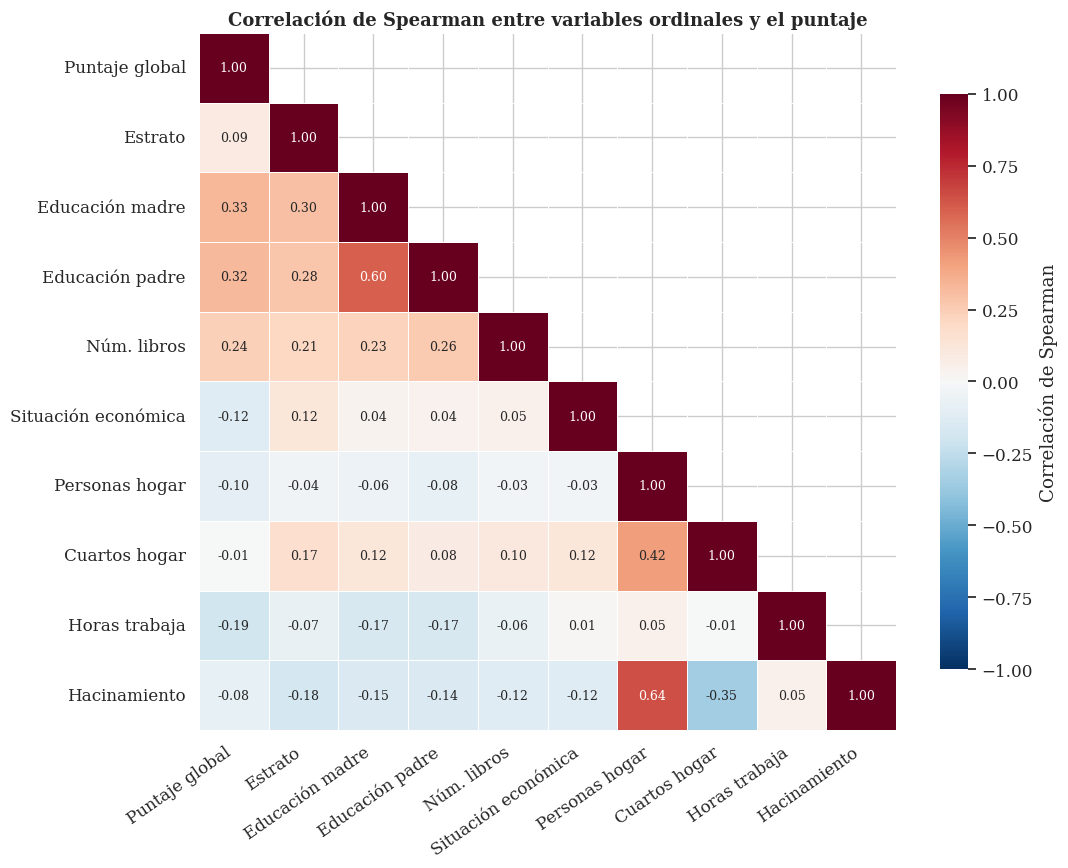

Correlación de cada variable con el puntaje global (ordenada por magnitud):
Educación madre        0.332
Educación padre        0.325
Núm. libros            0.237
Horas trabaja         -0.190
Situación económica   -0.122
Personas hogar        -0.096
Estrato                0.093
Hacinamiento          -0.079
Cuartos hogar         -0.007


In [ ]:
nombres = {
    "punt_global": "Puntaje global",
    "fami_estratovivienda_ord": "Estrato",
    "fami_educacionmadre_ord": "Educación madre",
    "fami_educacionpadre_ord": "Educación padre",
    "fami_numlibros_ord": "Núm. libros",
    "fami_situacioneconomica_ord": "Situación económica",
    "fami_personashogar_ord": "Personas hogar",
    "fami_cuartoshogar_ord": "Cuartos hogar",
    "estu_horassemanatrabaja_ord": "Horas trabaja",
    "hacinamiento": "Hacinamiento",
}

df_corr = df[list(nombres)].rename(columns=nombres)
corr = df_corr.corr(method="spearman")

# Mostrar solo el triángulo inferior (la matriz es simétrica)
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.6, linecolor="white",
            cbar_kws={"shrink": 0.8, "label": "Correlación de Spearman"},
            annot_kws={"fontsize": 9})
plt.title("Correlación de Spearman entre variables ordinales y el puntaje",
          fontsize=13, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Ranking de relación con el puntaje
print("Correlación de cada variable con el puntaje global (ordenada por magnitud):")
print(corr["Puntaje global"].drop("Puntaje global")
      .sort_values(key=abs, ascending=False).round(3).to_string())

**Resultados de la matriz de Spearman:**

- **Relación con el puntaje:** la educación de la madre (0.33) y del padre (0.32) son las variables ordinales más relacionadas con el puntaje, seguidas del número de libros (0.24). Las horas de trabajo tienen una relación negativa (−0.19): los estudiantes que trabajan más horas tienden a sacar menos puntaje. Las demás relaciones son débiles (menores a 0.13).

- **Variables que dicen lo mismo:** la educación de la madre y la del padre (0.60) y el hacinamiento y las personas del hogar (0.64) tienen una relación moderada. No es tan alta como para eliminar una de ellas, así que se dejan las dos.

### **η² (eta cuadrado)**

El η² mide qué parte de las diferencias de puntaje entre estudiantes se explica por la variable. Para calcularlo, se agrupan los estudiantes según su respuesta y se compara qué tanto se alejan los promedios de cada grupo del promedio general, frente a qué tanto varían todos los puntajes:

η² = variación entre grupos / variación total

Va de 0 (la variable no explica nada) a 1 (la variable explica todo el puntaje). Como solo necesita grupos, sirve para todas las variables: en las nominales cada categoría es un grupo, y en las ordinales cada nivel y cada respuesta fuera de escala también lo son. Así las 19 variables quedan medidas con el mismo número. Como referencia (Cohen, 1988), 0.01 es un efecto pequeño, 0.06 mediano y 0.14 grande.

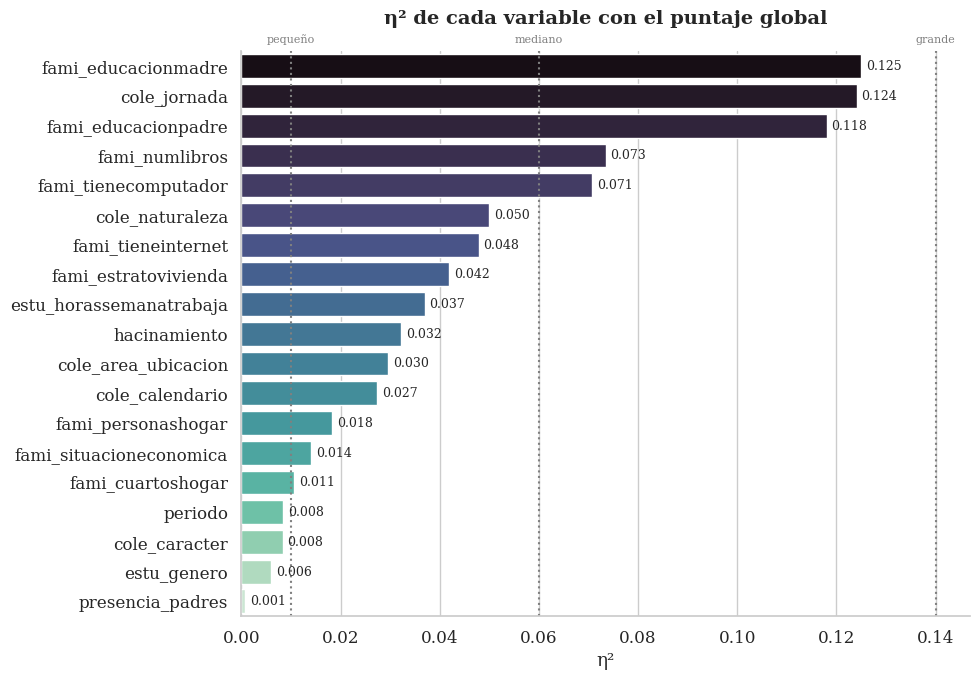

,0
fami_educacionmadre,0.1249
cole_jornada,0.1241
fami_educacionpadre,0.1180
fami_numlibros,0.0734
fami_tienecomputador,0.0708
cole_naturaleza,0.0500
fami_tieneinternet,0.0478
fami_estratovivienda,0.0419
estu_horassemanatrabaja,0.0369
hacinamiento,0.0323


In [ ]:
# Parte de la variación del puntaje que explica cada variable
def eta_cuadrado(grupos, puntaje):
    media = puntaje.mean()
    resumen = puntaje.groupby(grupos, dropna=False).agg(["count", "mean"])
    entre_grupos = (resumen["count"] * (resumen["mean"] - media) ** 2).sum()
    total = ((puntaje - media) ** 2).sum()
    return entre_grupos / total

variables_eta = list(variables_ordinales) + ["hacinamiento"] + variables_nominales
eta = pd.Series(
    {v: eta_cuadrado(df[v], df["punt_global"]) for v in variables_eta}
).sort_values(ascending=False)

# Gráfico
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=eta.values, y=eta.index, hue=eta.index,
            palette="mako", legend=False, ax=ax)
for i, v in enumerate(eta.values):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=9)
for limite, nombre in [(0.01, "pequeño"), (0.06, "mediano"), (0.14, "grande")]:
    ax.axvline(limite, color="gray", linestyle=":")
    ax.text(limite, -0.8, nombre, ha="center", fontsize=8, color="gray")
ax.set_title("η² de cada variable con el puntaje global",
             fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("η²")
ax.set_ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

eta.round(4)

**Resultados del η²:**

- **Variables más relacionadas con el puntaje:** la educación de la madre (0.125), la jornada (0.124) y la educación del padre (0.118) tienen un efecto mediano, cercano a grande. Les siguen el número de libros (0.073) y tener computador (0.071).
- **Efecto pequeño:** la naturaleza del colegio, tener internet, el estrato, las horas de trabajo, el hacinamiento, el área y el calendario están entre 0.027 y 0.050.
- **Efecto muy pequeño:** el periodo (0.009), el carácter del colegio (0.008), el género (0.006) y sobre todo `presencia_padres` (0.001), que afecta a muy pocos estudiantes.

Ninguna variable por sí sola explica más del 13% de las diferencias de puntaje. Esto anticipa que el modelo necesitará combinar muchas variables y que su capacidad de predicción será moderada.

### **V de Cramér**

La V de Cramér mide si dos variables nominales dicen lo mismo, es decir, si conocer una permite adivinar la otra. Se compara la tabla real de cruce entre las dos variables con la tabla que se esperaría si no tuvieran ninguna relación. Esa diferencia se ajusta por el número de estudiantes y de categorías, para que el resultado no crezca solo por tener muchos datos.

Va de 0 (las variables no tienen relación) a 1 (una variable determina a la otra). Es el equivalente de la matriz de Spearman para las variables nominales. Como referencia, para variables de dos categorías 0.1 es una relación débil, 0.3 moderada y 0.5 fuerte; con más categorías estos límites son algo menores.

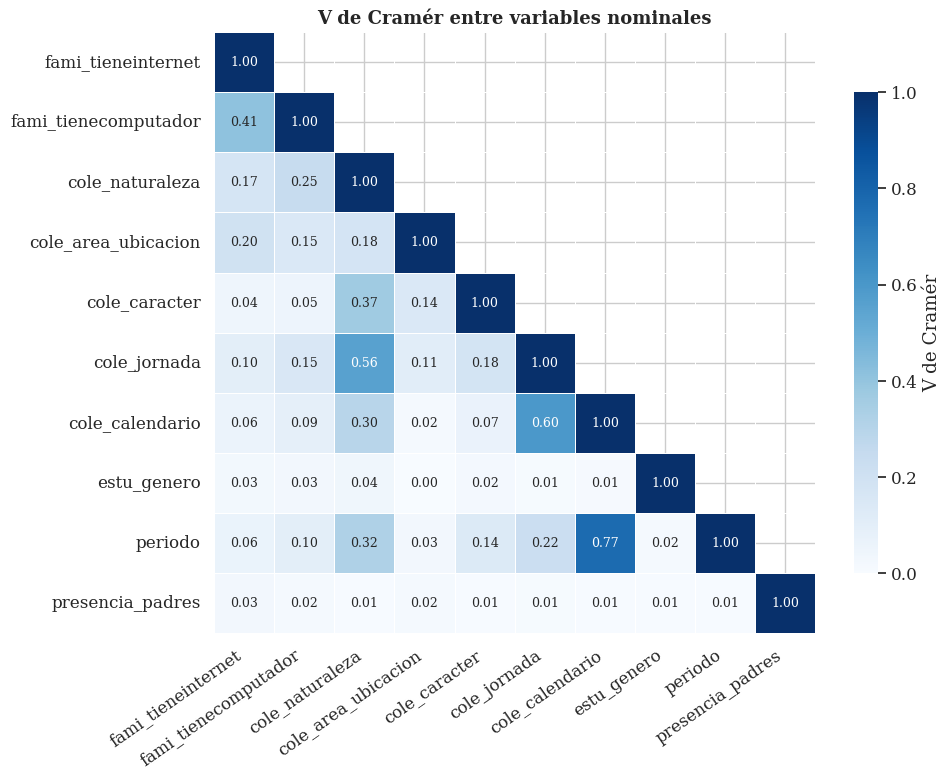

In [ ]:
# Relación entre cada par de variables nominales
def v_cramer(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    m = min(tabla.shape)
    return np.sqrt(chi2 / (n * (m - 1)))

matriz_v = pd.DataFrame(index=variables_nominales, columns=variables_nominales, dtype=float)
for a in variables_nominales:
    for b in variables_nominales:
        matriz_v.loc[a, b] = 1.0 if a == b else v_cramer(df[a], df[b])

# Mostrar solo el triángulo inferior (la matriz es simétrica)
mascara = np.triu(np.ones_like(matriz_v, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_v, mask=mascara, annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1, square=True, linewidths=0.6, linecolor="white",
            cbar_kws={"shrink": 0.8, "label": "V de Cramér"},
            annot_kws={"fontsize": 9})
plt.title("V de Cramér entre variables nominales", fontsize=13, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Resultados de la V de Cramér:**

- **Periodo y calendario (0.77):** es la relación más fuerte, porque el periodo 20251 corresponde principalmente a los colegios de calendario B. Aun así, no dicen exactamente lo mismo (la V no es 1): hay estudiantes del periodo 20251 que no son de calendario B.
- **Jornada con calendario (0.60) y con naturaleza (0.56):** relaciones fuertes, porque algunas jornadas son típicas de ciertos tipos de colegio (por ejemplo, la jornada completa o única en los colegios de calendario B y los no oficiales).
- **Relaciones moderadas:** Internet y computador (0.41), muchos hogares tienen los dos, pero muchos tienen solo uno, así que cada variable aporta información propia. La naturaleza del colegio con el carácter (0.37), el periodo (0.32) y el calendario (0.30).
- **Género y `presencia_padres`:** prácticamente no se relacionan con ninguna otra variable (V ≤ 0.04).

Ningún par de variables es redundante (ninguna V es cercana a 1), así que no se elimina ninguna por esta razón.

## **3. Separación de datos**

Los datos se dividen en dos conjuntos:

- **Entrenamiento (80%)**: con él se entrenan los modelos y se toman todas las decisiones (selección de variables e hiperparámetros).
- **Prueba (20%)**: se aparta y se usa una sola vez, al final, para medir qué tan bien predicen los modelos con estudiantes que nunca vieron.

**Decisiones:**

- **Relleno de vacíos con −1:** antes de dividir, los vacíos de las columnas ordinales se rellenan con −1, un valor fuera de la escala (0 a 1) que marca que esa respuesta no tiene nivel. La respuesta real del estudiante la conserva su variable indicadora.
- **Validación cruzada con 5 folds:** el entrenamiento se divide en 5 partes. Cada modelo se entrena 5 veces con 4 partes y se evalúa con la parte restante, y se reporta el promedio y la desviación estándar de los 5 resultados. Así el error no depende de una sola división.
- **Estratificación por periodo:** el periodo 20251 tiene solo el 3.8% de los estudiantes, así que se asegura que quede en la misma proporción en ambos conjuntos.
- **Semilla fija** (`random_state = 42`): para que los resultados sean los mismos cada vez que se ejecuta el notebook.
- **Mismos datos para todos los modelos:** todos usan el mismo conjunto de prueba y los mismos 5 folds, para que la comparación sea justa.

In [ ]:
from sklearn.model_selection import train_test_split, KFold

SEMILLA = 42

# Rellenar los vacíos de las ordinales con -1 (valor fuera de la escala 0 a 1)
X = df[cols_modelo].fillna(-1)
y = df["punt_global"].copy()

# Copia de las columnas para evaluar el modelo por grupos al final
cols_grupos = ["cole_depto_ubicacion", "cole_naturaleza",
               "cole_area_ubicacion", "periodo"]
grupos = df[cols_grupos].copy()

# División en train y test, estratificada por periodo
X_train, X_test, y_train, y_test, grupos_train, grupos_test = train_test_split(
    X, y, grupos,
    test_size=0.20,
    stratify=df["periodo"],
    random_state=SEMILLA,
)

# Validación cruzada con los mismos 5 folds para todos los modelos
kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Verificar la división
print(f"Train: {len(X_train):,} filas ({len(X_train)/len(X):.0%})")
print(f"Test:  {len(X_test):,} filas ({len(X_test)/len(X):.0%})")
print(f"Columnas del modelo: {X_train.shape[1]}\n")

print("% de estudiantes del periodo 20251:")
print(f"  Train: {(grupos_train['periodo'] == 20251).mean():.2%}")
print(f"  Test:  {(grupos_test['periodo'] == 20251).mean():.2%}")

Train: 455,339 filas (80%)
Test:  113,835 filas (20%)
Columnas del modelo: 45

% de estudiantes del periodo 20251:
  Train: 3.83%
  Test:  3.83%


## **4. Comparación de modelos**

Se comparan los modelos vistos en clase para elegir el que mejor se ajusta a los datos. Todos se evalúan en igualdad de condiciones:

- Las mismas 45 columnas (todavía sin selección de variables).
- Los mismos 5 folds del paso 3.
- La misma muestra de 150 mil estudiantes del entrenamiento, se deja un grupo de 100 mil para calcular la información mutua más adelante. Debe hacerse con otra parte del set de entrenamiento para no tomar decisiones con los mismos datos que se entrenaron los modelos.
- Sin ajustar hiperparámetros: Solo el modelo ganador se optimiza más adelante.

**Modelos:**
- **Regresión Lineal:** el modelo más simple. Es la línea base para medir cuánto mejoran los demás.
- **Árbol de decisión:** con profundidad máxima de 10.
- **Random Forest:** 100 árboles, cada uno entrenado con el 20% de la muestra (`max_samples=0.2`).
- **SVM:** se usa `LinearSVR`, la versión lineal del SVM para regresión.
- **HistGradientBoosting:** un modelo adicional, que no se vio en clase. Es un método de ensamble de árboles diseñado para muchos datos.

**Gaussian Naive Bayes no se usa** porque es un modelo de clasificación: predice categorías, no valores numéricos. Este problema es de regresión, porque el puntaje global es un número continuo entre 0 y 500.

**Métricas:** R², RMSE y MAE (promedio y desviación estándar de los 5 folds), y el tiempo de entrenamiento. También se mide el error en los datos de entrenamiento: si es mucho menor que el de validación, el modelo está sobreajustando.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import LinearSVR

# Dos muestras del train que no comparten estudiantes
idx_mezclado = X_train.sample(frac=1, random_state=SEMILLA).index
idx_eval = idx_mezclado[:150_000]          # para comparar modelos y elegir variables
idx_mi = idx_mezclado[150_000:250_000]     # para calcular la información mutua (paso 5)

X_eval = X_train.loc[idx_eval]
y_eval = y_train.loc[idx_eval]

modelos = {
    "Regresión Lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=10, random_state=SEMILLA),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_samples=0.2,
                                           n_jobs=-1, random_state=SEMILLA),
    # dual=False es la opción recomendada cuando hay muchos más datos que columnas
    "SVM (LinearSVR)": LinearSVR(loss="squared_epsilon_insensitive", dual=False,
                                 random_state=SEMILLA),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEMILLA),
}

In [ ]:
from sklearn.model_selection import cross_validate

metricas = {"R2": "r2",
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error"}

filas = []
for nombre, modelo in modelos.items():
    res = cross_validate(modelo, X_eval, y_eval, cv=kfold,
                         scoring=metricas, return_train_score=True)
    filas.append({
        "Modelo": nombre,
        "R2": res["test_R2"].mean(),
        "R2 desv.": res["test_R2"].std(),
        # sklearn devuelve RMSE y MAE en negativo, por eso se cambia el signo
        "RMSE": -res["test_RMSE"].mean(),
        "RMSE desv.": res["test_RMSE"].std(),
        "MAE": -res["test_MAE"].mean(),
        "RMSE entrenamiento": -res["train_RMSE"].mean(),
        "Tiempo (s)": res["fit_time"].mean(),
    })
    print(f"{nombre}: RMSE = {filas[-1]['RMSE']:.2f} ± {filas[-1]['RMSE desv.']:.2f}")

comparacion_modelos = pd.DataFrame(filas).set_index("Modelo").sort_values("RMSE").round(3)
comparacion_modelos

Regresión Lineal: RMSE = 45.86 ± 0.16
Árbol de decisión: RMSE = 46.66 ± 0.23
Random Forest: RMSE = 45.41 ± 0.14
SVM (LinearSVR): RMSE = 45.86 ± 0.16
HistGradientBoosting: RMSE = 44.48 ± 0.14


,R2,R2 desv.,RMSE,RMSE desv.,MAE,RMSE entrenamiento,Tiempo (s)
Modelo,,,,,,,
HistGradientBoosting,0.346,0.002,44.483,0.139,35.924,43.994,5.014
Random Forest,0.319,0.003,45.411,0.138,36.702,37.807,23.637
Regresión Lineal,0.305,0.002,45.862,0.163,37.171,45.848,0.330
SVM (LinearSVR),0.305,0.002,45.862,0.163,37.171,45.848,1.237
Árbol de decisión,0.281,0.004,46.661,0.226,37.690,45.504,0.742


In [ ]:
from sklearn.model_selection import cross_validate, cross_val_score

metricas = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}

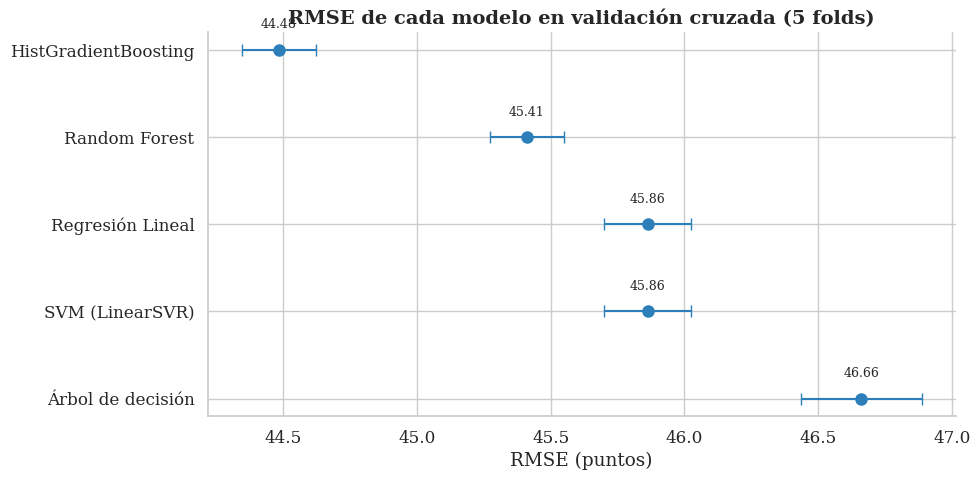

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(comparacion_modelos["RMSE"], comparacion_modelos.index,
            xerr=comparacion_modelos["RMSE desv."], fmt="o",
            color=color_acento, capsize=4, markersize=8)
for i, v in enumerate(comparacion_modelos["RMSE"]):
    ax.text(v, i - 0.25, f"{v:.2f}", ha="center", fontsize=9)
ax.invert_yaxis()
ax.set_title("RMSE de cada modelo en validación cruzada (5 folds)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("RMSE (puntos)")
sns.despine()
plt.tight_layout()
plt.show()

**Resultados de la comparación:**

- **HistGradientBoosting es el mejor modelo:** tiene el menor error (RMSE 44.48, R² 0.346), no sobreajusta (su error en entrenamiento, 43.99, es casi igual al de validación) y es rápido (unos 5 s por fold). Las diferencias con los demás modelos (entre 0.9 y 2.2 puntos) son mucho mayores que la variación entre folds (~0.15), así que no se deben al azar.
- **Random Forest** es el segundo, pero sobreajusta: su error en entrenamiento (37.8) es mucho menor que en validación (45.4). Además es el más lento.
- **Regresión Lineal y SVM** dan el mismo resultado (RMSE 45.86), porque ambos son modelos lineales.
- **El árbol de decisión** es el peor, incluso peor que la regresión lineal: un solo árbol hace cortes bruscos y no capta bien las relaciones graduales entre las variables y el puntaje.

**Interpretación:** los modelos de ensamble de árboles (HGB y Random Forest) superan a la línea base, lo que indica que hay relaciones no lineales e interacciones entre las variables.

**Modelo elegido:** HistGradientBoosting. Es el que se usa para la selección de variables y el que se optimiza y se compara con la red neuronal más adelante. La Regresión Lineal se conserva como línea base para la evaluación final.

## **5. Selección de características**

**Método:** información mutua (`mutual_info_regression`) con `SelectKBest`.
La información mutua mide cuánto se reduce la incertidumbre sobre el puntaje al conocer una variable. A diferencia de la correlación, detecta relaciones no lineales y funciona con cualquier tipo de variable. Además no depende de ningún modelo.

**Procedimiento:**
1. Se calcula la información mutua de cada **variable original** con el puntaje. La selección es por variable completa: una variable se conserva o se descarta junto con todas sus columnas (su nivel y sus variables indicadoras, o todas sus columnas one-hot).
2. Se ordenan las variables de mayor a menor información mutua.
3. Se evalúa con k-fold el modelo ganador del paso 4 (HistGradientBoosting) usando las *k* variables con más información mutua, para *k* = 1, …, 19.
4. Se elige el **menor k cuyo error esté dentro de una desviación estándar del mejor resultado**, el modelo más simple que rinde igual que el mejor.


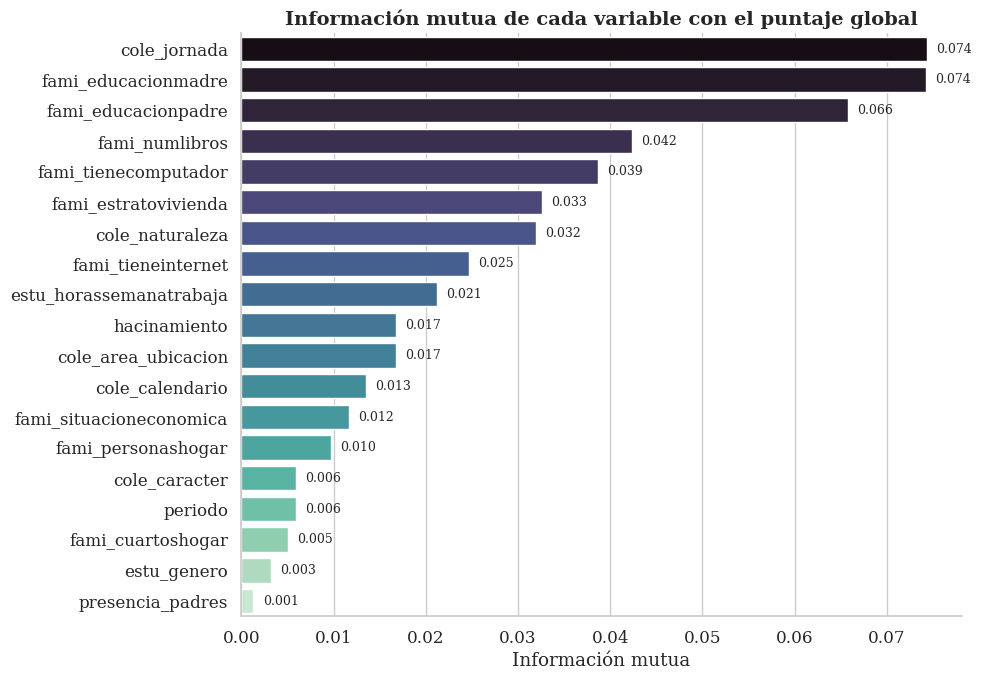

,0
cole_jornada,0.0744
fami_educacionmadre,0.0742
fami_educacionpadre,0.0658
fami_numlibros,0.0423
fami_tienecomputador,0.0387
fami_estratovivienda,0.0326
cole_naturaleza,0.0320
fami_tieneinternet,0.0247
estu_horassemanatrabaja,0.0212
hacinamiento,0.0168


In [ ]:
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_regression

# Las 19 variables y las columnas que ocupa cada una en el modelo
variables = list(variables_ordinales) + ["hacinamiento"] + variables_nominales

cols_por_variable = {
    v: [f"{v}_ord"] + indicadoras[v]
    for v in variables_ordinales
}
cols_por_variable["hacinamiento"] = ["hacinamiento"]
cols_por_variable.update({
    v: [c for c in cols_onehot_nominales if c.startswith(f"{v}__")]
    for v in variables_nominales
})

# Información mutua de cada variable con el puntaje (muestra idx_mi del paso 4)
# Cada respuesta (incluidas las fuera de escala) se trata como un valor distinto
V_mi = df.loc[idx_mi, list(variables_ordinales) + variables_nominales].apply(lambda s: pd.factorize(s)[0])
V_mi["hacinamiento"] = pd.factorize(X_train.loc[idx_mi, "hacinamiento"])[0]
V_mi = V_mi[variables]

selector = SelectKBest(score_func=partial(mutual_info_regression, discrete_features=True, random_state=SEMILLA), k="all")
selector.fit(V_mi, y_train.loc[idx_mi])

ranking = pd.Series(selector.scores_, index=variables).sort_values(ascending=False)

# Gráfico
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=ranking.values, y=ranking.index, hue=ranking.index,
            palette="mako", legend=False, ax=ax)
for i, v in enumerate(ranking.values):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_title("Información mutua de cada variable con el puntaje global",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Información mutua")
ax.set_ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

ranking.round(4)

In [ ]:
from sklearn.model_selection import cross_val_score

# Evaluar HGB con las k variables de mayor información mutua (muestra idx_eval del paso 4)
resultados = []
for k in range(1, len(variables) + 1):
    vars_k = list(ranking.index[:k])
    cols_k = [c for v in vars_k for c in cols_por_variable[v]]

    modelo = HistGradientBoostingRegressor(random_state=SEMILLA)
    rmse = -cross_val_score(modelo, X_eval[cols_k], y_eval, cv=kfold,
                            scoring="neg_root_mean_squared_error")

    resultados.append({"k": k, "variable_agregada": vars_k[-1],
                       "rmse_medio": rmse.mean(), "rmse_std": rmse.std()})
    print(f"k={k:2d} | +{vars_k[-1]:<28} | RMSE = {rmse.mean():.2f} ± {rmse.std():.2f}")

resultados = pd.DataFrame(resultados)

k= 1 | +cole_jornada                 | RMSE = 51.49 ± 0.23
k= 2 | +fami_educacionmadre          | RMSE = 48.97 ± 0.19
k= 3 | +fami_educacionpadre          | RMSE = 48.34 ± 0.19
k= 4 | +fami_numlibros               | RMSE = 47.85 ± 0.18
k= 5 | +fami_tienecomputador         | RMSE = 47.50 ± 0.22
k= 6 | +fami_estratovivienda         | RMSE = 46.86 ± 0.18
k= 7 | +cole_naturaleza              | RMSE = 46.46 ± 0.16
k= 8 | +fami_tieneinternet           | RMSE = 46.37 ± 0.16
k= 9 | +estu_horassemanatrabaja      | RMSE = 46.04 ± 0.15
k=10 | +hacinamiento                 | RMSE = 45.68 ± 0.15
k=11 | +cole_area_ubicacion          | RMSE = 45.41 ± 0.14
k=12 | +cole_calendario              | RMSE = 45.37 ± 0.14
k=13 | +fami_situacioneconomica      | RMSE = 44.89 ± 0.14
k=14 | +fami_personashogar           | RMSE = 44.88 ± 0.13
k=15 | +cole_caracter                | RMSE = 44.77 ± 0.14
k=16 | +periodo                      | RMSE = 44.76 ± 0.14
k=17 | +fami_cuartoshogar            | RMSE = 44.76 ± 0.

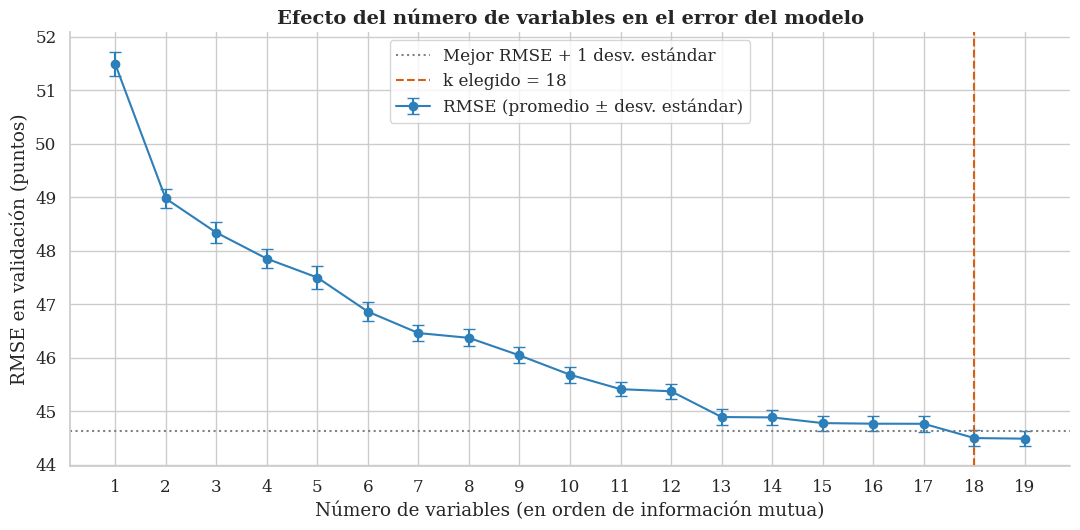

Todas las variables (k = 19): RMSE = 44.48
Mejor RMSE: 44.48 con k = 19
k elegido: 18 (RMSE = 44.49)

Variables seleccionadas (18): ['cole_jornada', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_numlibros', 'fami_tienecomputador', 'fami_estratovivienda', 'cole_naturaleza', 'fami_tieneinternet', 'estu_horassemanatrabaja', 'hacinamiento', 'cole_area_ubicacion', 'cole_calendario', 'fami_situacioneconomica', 'fami_personashogar', 'cole_caracter', 'periodo', 'fami_cuartoshogar', 'estu_genero']

Variables descartadas (1): ['presencia_padres']

Columnas del modelo: 42 de 45


In [ ]:
# Regla de una desviación estándar
mejor = resultados.loc[resultados["rmse_medio"].idxmin()]
umbral = mejor["rmse_medio"] + mejor["rmse_std"]
k_elegido = int(resultados.loc[resultados["rmse_medio"] <= umbral, "k"].min())

vars_seleccionadas = list(ranking.index[:k_elegido])
cols_seleccionadas = [c for v in vars_seleccionadas for c in cols_por_variable[v]]
vars_descartadas = list(ranking.index[k_elegido:])

# Gráfico
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.errorbar(resultados["k"], resultados["rmse_medio"], yerr=resultados["rmse_std"],
            marker="o", color=color_acento, capsize=4, label="RMSE (promedio ± desv. estándar)")
ax.axhline(umbral, color="gray", linestyle=":", label="Mejor RMSE + 1 desv. estándar")
ax.axvline(k_elegido, color=color_secundario, linestyle="--", label=f"k elegido = {k_elegido}")
ax.set_xticks(resultados["k"])
ax.set_xlabel("Número de variables (en orden de información mutua)")
ax.set_ylabel("RMSE en validación (puntos)")
ax.set_title("Efecto del número de variables en el error del modelo",
             fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

print(f"Todas las variables (k = {len(variables)}): RMSE = "
      f"{resultados['rmse_medio'].iloc[-1]:.2f}")
print(f"Mejor RMSE: {mejor['rmse_medio']:.2f} con k = {int(mejor['k'])}")
print(f"k elegido: {k_elegido} (RMSE = "
      f"{resultados.loc[resultados['k'] == k_elegido, 'rmse_medio'].item():.2f})\n")
print(f"Variables seleccionadas ({len(vars_seleccionadas)}): {vars_seleccionadas}\n")
print(f"Variables descartadas ({len(vars_descartadas)}): {vars_descartadas}\n")
print(f"Columnas del modelo: {len(cols_seleccionadas)} de {len(cols_modelo)}")

**Resultados de la selección:**

- **Se eligieron 18 de las 19 variables.** El mejor error se obtiene con todas (RMSE 44.48), pero con 18 el error es prácticamente igual (44.49): la diferencia de 0.01 puntos es mucho menor que la variación entre folds (0.14). Según la regla de una desviación estándar, se prefiere el modelo más simple.
- **Se descarta `presencia_padres`.** Afecta a pocos estudiantes, así que casi no cambia el error global.

Las 18 variables seleccionadas (`cols_seleccionadas`, 42 columnas) se usan tanto para HistGradientBoosting como para la red neuronal.

## **6. Optimización de hiperparámetros de HistGradientBoosting**

**Método:** optimización bayesiana con **Optuna**. En lugar de probar todas las combinaciones (GridSearch) o combinaciones al azar (RandomizedSearch), Optuna usa los resultados de los intentos anteriores para elegir el siguiente, concentrándose en las zonas donde el error es menor.

**Hiperparámetros que se optimizan:**
- `learning_rate`: cuánto corrige cada árbol los errores de los anteriores. Valores pequeños son más precisos, pero necesitan más árboles.
- `max_leaf_nodes`: número máximo de hojas de cada árbol, es decir, qué tan complejo es cada árbol.
- `min_samples_leaf`: número mínimo de estudiantes en cada hoja. Valores grandes evitan que el modelo se ajuste a casos muy particulares.

El número de árboles (`max_iter`) se fija en 500 con **parada temprana**: el modelo aparta el 10% de sus datos de entrenamiento y deja de agregar árboles cuando el error deja de mejorar. Así el número de árboles se ajusta solo.

**Evaluación:** cada combinación se evalúa con los mismos 5 folds, la misma muestra de 150 mil estudiantes y las 18 variables seleccionadas. Se prueban 40 combinaciones. Al final, el modelo optimizado se compara con el modelo con los valores por defecto, con los mismos folds, para medir la mejora.

In [ ]:
!pip install optuna -q

In [ ]:
import optuna

# Ocultar los mensajes de cada intento (se muestra solo la barra de progreso)
optuna.logging.set_verbosity(optuna.logging.WARNING)

X_sel = X_eval[cols_seleccionadas]

def objetivo(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.3, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 15, 127),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 1000, log=True),
    }
    modelo = HistGradientBoostingRegressor(**params, max_iter=500,
                                           early_stopping=True, random_state=SEMILLA)
    rmse = -cross_val_score(modelo, X_sel, y_eval, cv=kfold,
                            scoring="neg_root_mean_squared_error")
    return rmse.mean()

estudio = optuna.create_study(direction="minimize",
                              sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=40, show_progress_bar=True)

mejores_params = estudio.best_params
print(f"Mejor RMSE en la búsqueda: {estudio.best_value:.2f}")
print("Mejores hiperparámetros:")
for nombre, valor in mejores_params.items():
    print(f"  {nombre}: {valor}")

  0%|          | 0/40 [00:00<?, ?it/s]

Mejor RMSE en la búsqueda: 44.40
Mejores hiperparámetros:
  learning_rate: 0.044408018452902175
  max_leaf_nodes: 33
  min_samples_leaf: 62


In [ ]:
# Resultados guardados de los pasos 5 y 6
k_elegido = 18
vars_seleccionadas = list(ranking.index[:k_elegido])
cols_seleccionadas = [c for v in vars_seleccionadas for c in cols_por_variable[v]]

mejores_params = {"learning_rate": 0.044408018452902175,
                  "max_leaf_nodes": 33,
                  "min_samples_leaf": 62}
X_sel = X_eval[cols_seleccionadas]

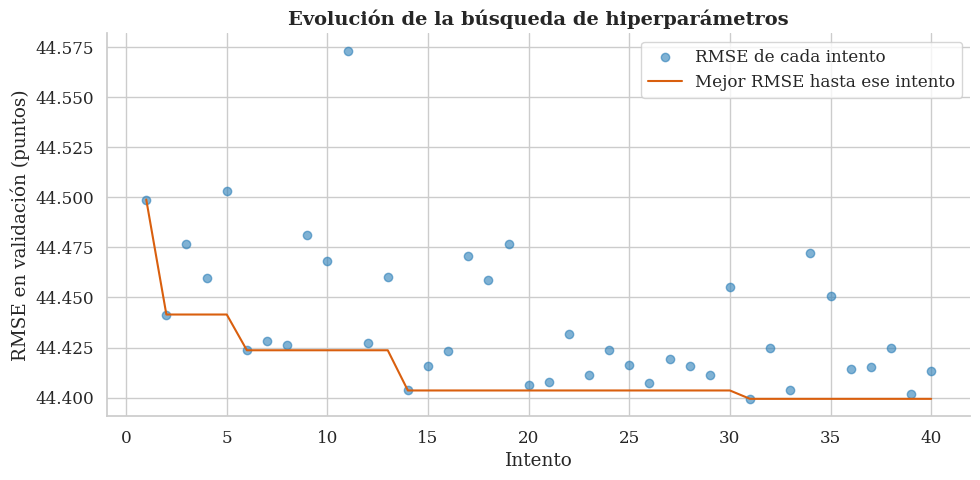

In [ ]:
# RMSE de cada intento y el mejor encontrado hasta ese momento
intentos = estudio.trials_dataframe()
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(intentos["number"] + 1, intentos["value"], color=color_acento,
           alpha=0.6, label="RMSE de cada intento")
ax.plot(intentos["number"] + 1, intentos["value"].cummin(), color=color_secundario,
        label="Mejor RMSE hasta ese intento")
ax.set_xlabel("Intento")
ax.set_ylabel("RMSE en validación (puntos)")
ax.set_title("Evolución de la búsqueda de hiperparámetros",
             fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
modelos_hgb = {
    "HGB por defecto": HistGradientBoostingRegressor(random_state=SEMILLA),
    "HGB optimizado": HistGradientBoostingRegressor(**mejores_params, max_iter=500,
                                                    early_stopping=True,
                                                    random_state=SEMILLA),
}

filas = []
for nombre, modelo in modelos_hgb.items():
    res = cross_validate(modelo, X_sel, y_eval, cv=kfold,
                         scoring=metricas, return_train_score=True)
    filas.append({
        "Modelo": nombre,
        "R2": res["test_R2"].mean(),
        "RMSE": -res["test_RMSE"].mean(),
        "RMSE desv.": res["test_RMSE"].std(),
        "MAE": -res["test_MAE"].mean(),
        "RMSE entrenamiento": -res["train_RMSE"].mean(),
        "Tiempo (s)": res["fit_time"].mean(),
    })

comparacion_hgb = pd.DataFrame(filas).set_index("Modelo").round(3)
comparacion_hgb

,R2,RMSE,RMSE desv.,MAE,RMSE entrenamiento,Tiempo (s)
Modelo,,,,,,
HGB por defecto,0.346,44.494,0.143,35.932,44.005,3.751
HGB optimizado,0.349,44.399,0.138,35.815,43.616,12.840


In [ ]:
# Comparar el RMSE de los dos modelos en cada fold (mismos folds)
rmse_por_fold = pd.DataFrame({
    nombre: -cross_val_score(modelo, X_sel, y_eval, cv=kfold,
                             scoring="neg_root_mean_squared_error")
    for nombre, modelo in modelos_hgb.items()
}, index=[f"Fold {i}" for i in range(1, 6)])
rmse_por_fold["Diferencia"] = rmse_por_fold["HGB optimizado"] - rmse_por_fold["HGB por defecto"]
rmse_por_fold.round(3)

,HGB por defecto,HGB optimizado,Diferencia
Fold 1,44.359,44.265,-0.095
Fold 2,44.293,44.215,-0.078
Fold 3,44.647,44.551,-0.096
Fold 4,44.545,44.430,-0.115
Fold 5,44.628,44.537,-0.092


**Resultados de la optimización:**

- **Mejores hiperparámetros encontrados:** `learning_rate` = 0.044, `max_leaf_nodes` = 33, `min_samples_leaf` = 62.
- **Mejora:** el RMSE baja de 44.49 a 44.40 (0.1 puntos) y el R² sube de 0.346 a 0.349. Como los dos modelos se evaluaron con los mismos folds, se comparan fold por fold: el modelo optimizado tiene menor error **en los 5 folds**, con diferencias muy parecidas entre ellos (entre 0.08 y 0.12 puntos). La mejora es pequeña pero consistente, no se debe al azar.
- **Costo:** el modelo optimizado tarda unas 3 veces más en entrenar (15 s frente a 4.6 s por fold) y su distancia entre el error de entrenamiento y el de validación es un poco mayor (0.78 frente a 0.49 puntos), aunque sigue siendo pequeña.

**Interpretación:** HistGradientBoosting es poco sensible a sus hiperparámetros: casi todas las combinaciones probadas dieron errores parecidos (todas entre 44.40 y 44.57). Esto confirma que el límite del desempeño está en la información que contienen las variables, más que en la configuración del modelo. Se usa el modelo optimizado en los pasos siguientes.

## **7. Curva de aprendizaje del modelo elegido**

La curva de aprendizaje muestra cómo cambia el error de HistGradientBoosting optimizado (con las 18 variables seleccionadas) a medida que se entrena con más estudiantes. Se compara el error en los datos de entrenamiento y en validación, con los mismos 5 folds y usando todo el conjunto de entrenamiento.

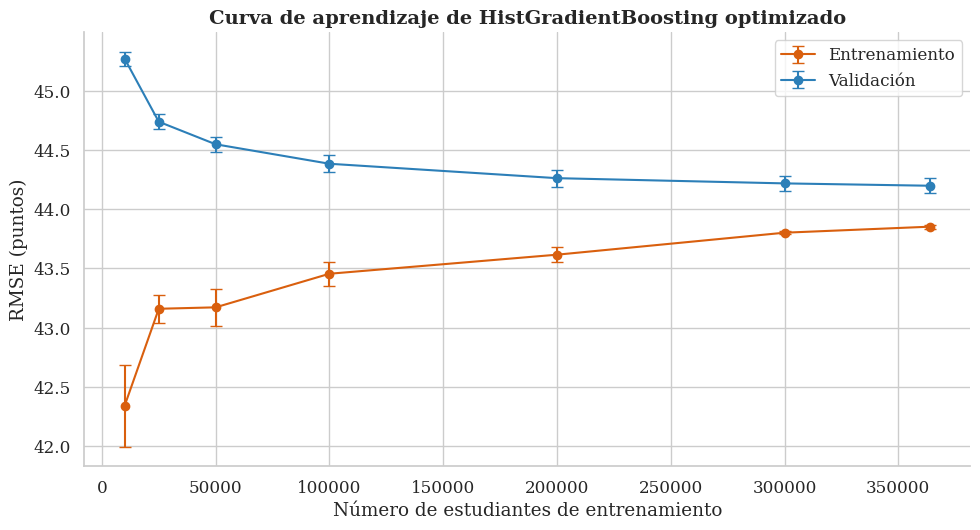

 10,000 estudiantes | RMSE entrenamiento = 42.34 | validación = 45.27
 25,000 estudiantes | RMSE entrenamiento = 43.16 | validación = 44.74
 50,000 estudiantes | RMSE entrenamiento = 43.17 | validación = 44.55
100,000 estudiantes | RMSE entrenamiento = 43.46 | validación = 44.39
200,000 estudiantes | RMSE entrenamiento = 43.62 | validación = 44.26
300,000 estudiantes | RMSE entrenamiento = 43.80 | validación = 44.22
364,000 estudiantes | RMSE entrenamiento = 43.85 | validación = 44.20


In [ ]:
from sklearn.model_selection import learning_curve

tamanos, rmse_train, rmse_valid = learning_curve(
    modelos_hgb["HGB optimizado"],
    X_train[cols_seleccionadas], y_train,
    train_sizes=[10_000, 25_000, 50_000, 100_000, 200_000, 300_000, 364_000],
    cv=kfold, scoring="neg_root_mean_squared_error",
)
# sklearn devuelve el RMSE en negativo, por eso se cambia el signo
rmse_train, rmse_valid = -rmse_train, -rmse_valid

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(tamanos, rmse_train.mean(axis=1), yerr=rmse_train.std(axis=1),
            marker="o", color=color_secundario, capsize=4, label="Entrenamiento")
ax.errorbar(tamanos, rmse_valid.mean(axis=1), yerr=rmse_valid.std(axis=1),
            marker="o", color=color_acento, capsize=4, label="Validación")
ax.set_xlabel("Número de estudiantes de entrenamiento")
ax.set_ylabel("RMSE (puntos)")
ax.set_title("Curva de aprendizaje de HistGradientBoosting optimizado",
             fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

for n, tr, va in zip(tamanos, rmse_train.mean(axis=1), rmse_valid.mean(axis=1)):
    print(f"{n:>7,} estudiantes | RMSE entrenamiento = {tr:.2f} | validación = {va:.2f}")

**Resultados de la curva de aprendizaje:**

- **El modelo se estabilizó:** el error de validación baja de 45.27 (10 mil estudiantes) a 44.39 (100 mil), y después casi no cambia: entre 300 mil y 364 mil estudiantes mejora solo 0.02 puntos. Agregar más datos del mismo tipo casi no mejoraría el modelo.
- **No hay sobreajuste:** con 364 mil estudiantes, el error de entrenamiento (43.85) y el de validación (44.20) están a solo 0.35 puntos, y las dos curvas se acercan entre sí.
- **El límite está en las variables:** las dos curvas se acercan a unos 44 puntos y no bajan más. El modelo no se equivoca por memorizar los datos, sino porque las variables socioeconómicas y escolares no tienen suficiente información para predecir mejor el puntaje. Mejorar el modelo requeriría variables nuevas, no más estudiantes.

## **Red neuronal**

Se entrena una red neuronal densa (perceptrón multicapa) para compararla con el mejor modelo de machine learning (HistGradientBoosting optimizado).

**Arquitectura base:**
- **Dos capas ocultas** de 128 y 64 neuronas con activación **ReLU**, que permite aprender relaciones no lineales.
- **Dropout de 0.2** después de cada capa: en cada paso del entrenamiento se apaga al azar el 20% de las neuronas, para que la red no dependa de unas pocas y no sobreajuste.
- **Una neurona de salida sin activación**, porque la red debe predecir un número (el puntaje).

**Entrenamiento:**
- **Pérdida MSE** (error cuadrático medio), la misma que minimizan los modelos de regresión.
- **Optimizador Adam** con tasa de aprendizaje 0.001, el más usado para redes neuronales porque ajusta automáticamente el tamaño de cada paso.
- **Parada temprana:** se aparta el 10% de los datos de entrenamiento de cada fold. Si el error en esa parte no mejora durante 5 épocas seguidas, el entrenamiento se detiene y se recuperan los pesos de la mejor época. Así no hay que fijar el número de épocas y se evita el sobreajuste.
- **Puntaje estandarizado:** para entrenar, al puntaje se le resta su media y se divide por su desviación estándar (calculadas solo con el entrenamiento de cada fold). Las redes aprenden mejor con valores cercanos a 0. Las predicciones se vuelven a convertir a puntos antes de calcular las métricas.

**Evaluación:** los mismos 5 folds, la misma muestra de 150 mil estudiantes y las mismas 18 variables seleccionadas que HistGradientBoosting, para que la comparación sea justa. Las variables de entrada ya están entre −1 y 1 por el encoding del paso 1, así que no necesitan otro escalado.

In [ ]:
import time
import tensorflow as tf
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("GPU disponible:", tf.config.list_physical_devices("GPU"))
tf.keras.utils.set_random_seed(SEMILLA)

def crear_red(n_entradas, neuronas=(128, 64), dropout=0.2, tasa_aprendizaje=1e-3):
    red = tf.keras.Sequential([tf.keras.Input(shape=(n_entradas,))])
    # Una capa densa con ReLU y un Dropout por cada valor de la lista de neuronas
    for n in neuronas:
        red.add(tf.keras.layers.Dense(n, activation=tf.nn.relu))
        red.add(tf.keras.layers.Dropout(dropout))
    # Salida lineal porque se predice un número (el puntaje)
    red.add(tf.keras.layers.Dense(1, activation="linear"))
    red.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
                loss="mse")
    return red

def evaluar_red(X, y, neuronas=(128, 64), dropout=0.2, tasa_aprendizaje=1e-3, tamano_lote=512):
    filas, historiales = [], []
    for fold, (i_tr, i_va) in enumerate(kfold.split(X), start=1):
        X_tr = X.iloc[i_tr].to_numpy("float32")
        X_va = X.iloc[i_va].to_numpy("float32")
        y_tr, y_va = y.iloc[i_tr].to_numpy(), y.iloc[i_va].to_numpy()

        # Estandarizar el puntaje con la media y la desviación del entrenamiento del fold
        media, desv = y_tr.mean(), y_tr.std()

        red = crear_red(X.shape[1], neuronas, dropout, tasa_aprendizaje)
        parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                  restore_best_weights=True)
        inicio = time.time()
        hist = red.fit(X_tr, (y_tr - media) / desv, validation_split=0.1, epochs=100,
                       batch_size=tamano_lote, callbacks=[parada], verbose=0)
        tiempo = time.time() - inicio

        # Volver a convertir las predicciones a puntos
        pred_va = red.predict(X_va, batch_size=4096, verbose=0).ravel() * desv + media
        pred_tr = red.predict(X_tr, batch_size=4096, verbose=0).ravel() * desv + media

        filas.append({
            "R2": r2_score(y_va, pred_va),
            "RMSE": mean_squared_error(y_va, pred_va) ** 0.5,
            "MAE": mean_absolute_error(y_va, pred_va),
            "RMSE entrenamiento": mean_squared_error(y_tr, pred_tr) ** 0.5,
            "Épocas": len(hist.history["loss"]),
            "Tiempo (s)": tiempo,
        })
        historiales.append(hist.history)
        print(f"Fold {fold}: RMSE = {filas[-1]['RMSE']:.2f} "
              f"({filas[-1]['Épocas']} épocas, {tiempo:.0f} s)")
    return pd.DataFrame(filas), historiales

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
X_red = X_eval[cols_seleccionadas]
res_red, historiales = evaluar_red(X_red, y_eval)

# Resumen de la red en el mismo formato que la tabla de HGB
fila_red = pd.DataFrame({
    "R2": [res_red["R2"].mean()],
    "RMSE": [res_red["RMSE"].mean()],
    "RMSE desv.": [res_red["RMSE"].std(ddof=0)],
    "MAE": [res_red["MAE"].mean()],
    "RMSE entrenamiento": [res_red["RMSE entrenamiento"].mean()],
    "Tiempo (s)": [res_red["Tiempo (s)"].mean()],
}, index=["Red neuronal (base)"])

comparacion_red = pd.concat([comparacion_hgb, fila_red]).round(3)
comparacion_red

Fold 1: RMSE = 44.65 (24 épocas, 20 s)
Fold 2: RMSE = 44.46 (34 épocas, 24 s)
Fold 3: RMSE = 44.90 (19 épocas, 15 s)
Fold 4: RMSE = 44.77 (19 épocas, 16 s)
Fold 5: RMSE = 44.89 (24 épocas, 18 s)


,R2,RMSE,RMSE desv.,MAE,RMSE entrenamiento,Tiempo (s)
HGB por defecto,0.346,44.494,0.143,35.932,44.005,3.751
HGB optimizado,0.349,44.399,0.138,35.815,43.616,12.840
Red neuronal (base),0.339,44.733,0.165,36.163,44.314,18.774


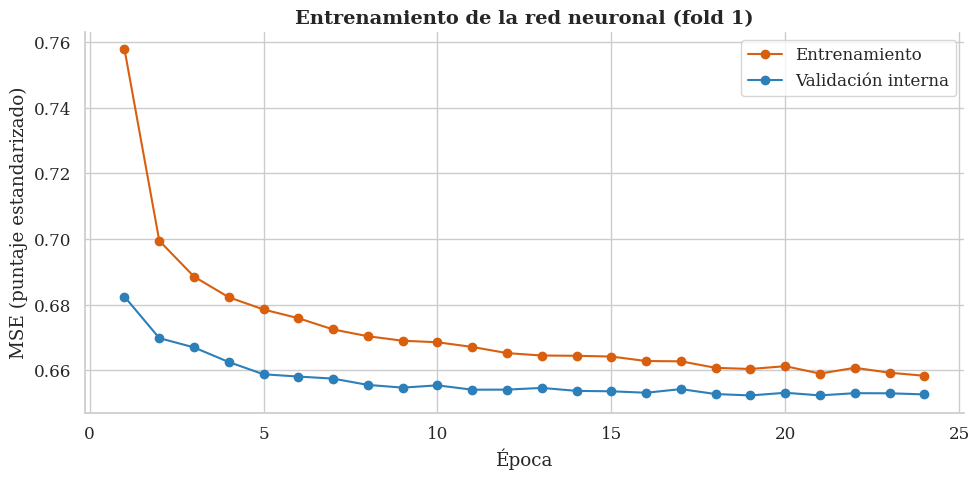

In [ ]:
# Error en entrenamiento y en la validación interna durante el entrenamiento (fold 1)
h = historiales[0]
epocas = range(1, len(h["loss"]) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epocas, h["loss"], marker="o", color=color_secundario, label="Entrenamiento")
ax.plot(epocas, h["val_loss"], marker="o", color=color_acento, label="Validación interna")
ax.set_xlabel("Época")
ax.set_ylabel("MSE (puntaje estandarizado)")
ax.set_title("Entrenamiento de la red neuronal (fold 1)", fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

**Resultados de la red neuronal base:**

- **Es comparable con los mejores modelos de machine learning:** su RMSE (44.73, R² 0.339) es mejor que el de la regresión lineal (45.86) y el de Random Forest (45.41), y queda a solo 0.33 puntos de HistGradientBoosting optimizado (44.40).
- **No sobreajusta:** su error en entrenamiento (44.31) y en validación (44.73) son casi iguales.
- **Entrenamiento:** el error de validación interna se estabiliza hacia la época 10, y la parada temprana detiene el entrenamiento entre las épocas 19 y 34. En el gráfico, el error de entrenamiento queda por encima del de validación porque el Dropout solo actúa durante el entrenamiento: en cada paso se apaga el 20% de las neuronas, mientras que al validar la red funciona completa.

Como la red no sobreajusta, en la optimización se prueban valores menores de dropout, redes más grandes y distintas tasas de aprendizaje.

### Optimización de la red neuronal

Se usa Optuna, igual que con HistGradientBoosting. Los hiperparámetros que se optimizan son:

- **Número de capas ocultas:** 2 o 3.
- **Neuronas de la primera capa:** 64, 128, 256 o 512. Cada capa siguiente tiene la mitad de neuronas que la anterior (por ejemplo, 256 → 128 → 64), una estructura común en redes densas.
- **Dropout:** entre 0 y 0.4.
- **Tasa de aprendizaje:** entre 0.0001 y 0.01.
- **Tamaño de lote:** 256, 512, 1024 o 2048 estudiantes por paso de entrenamiento.

**Evaluación más rápida durante la búsqueda:** entrenar cada combinación con los 5 folds tomaría demasiado tiempo. Por eso, durante la búsqueda cada combinación se evalúa con una sola división: la del primer fold (80% para entrenar y 20% para validar). Esa división solo sirve para comparar las combinaciones entre sí. Al final, la mejor combinación se evalúa con los 5 folds, igual que la red base y HistGradientBoosting, para que la comparación sea justa. Se prueban 30 combinaciones.

In [ ]:
!pip install optuna -q

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# División del primer fold para evaluar cada combinación durante la búsqueda
i_tr, i_va = next(kfold.split(X_red))
X_tr_opt = X_red.iloc[i_tr].to_numpy("float32")
X_va_opt = X_red.iloc[i_va].to_numpy("float32")
y_tr_opt, y_va_opt = y_eval.iloc[i_tr].to_numpy(), y_eval.iloc[i_va].to_numpy()
media_opt, desv_opt = y_tr_opt.mean(), y_tr_opt.std()

def objetivo_red(trial):
    n_capas = trial.suggest_int("n_capas", 2, 3)
    primera = trial.suggest_categorical("neuronas_primera_capa", [64, 128, 256, 512])
    # Cada capa tiene la mitad de neuronas que la anterior
    neuronas = tuple(primera // 2**i for i in range(n_capas))
    dropout = trial.suggest_float("dropout", 0.0, 0.4)
    tasa = trial.suggest_float("tasa_aprendizaje", 1e-4, 1e-2, log=True)
    lote = trial.suggest_categorical("tamano_lote", [256, 512, 1024, 2048])

    # Liberar la memoria de la red anterior y fijar la semilla
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)

    red = crear_red(X_red.shape[1], neuronas, dropout, tasa)
    parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                              restore_best_weights=True)
    red.fit(X_tr_opt, (y_tr_opt - media_opt) / desv_opt, validation_split=0.1,
            epochs=100, batch_size=lote, callbacks=[parada], verbose=0)

    pred = red.predict(X_va_opt, batch_size=4096, verbose=0).ravel() * desv_opt + media_opt
    return mean_squared_error(y_va_opt, pred) ** 0.5

estudio_red = optuna.create_study(direction="minimize",
                                  sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio_red.optimize(objetivo_red, n_trials=30, show_progress_bar=True)

mejores_params_red = estudio_red.best_params
print(f"Mejor RMSE en la búsqueda: {estudio_red.best_value:.2f}")
print("Mejores hiperparámetros:")
for nombre, valor in mejores_params_red.items():
    print(f"  {nombre}: {valor}")

  0%|          | 0/30 [00:00<?, ?it/s]

Mejor RMSE en la búsqueda: 44.61
Mejores hiperparámetros:
  n_capas: 2
  neuronas_primera_capa: 256
  dropout: 0.21526798105119516
  tasa_aprendizaje: 0.0004191804884400467
  tamano_lote: 256


In [ ]:
# Hiperparámetros encontrados por Optuna para la red (se fijan para no repetir la búsqueda)
mejores_params_red = {"n_capas": 2,
                      "neuronas_primera_capa": 256,
                      "dropout": 0.21526798105119516,
                      "tasa_aprendizaje": 0.0004191804884400467,
                      "tamano_lote": 256}

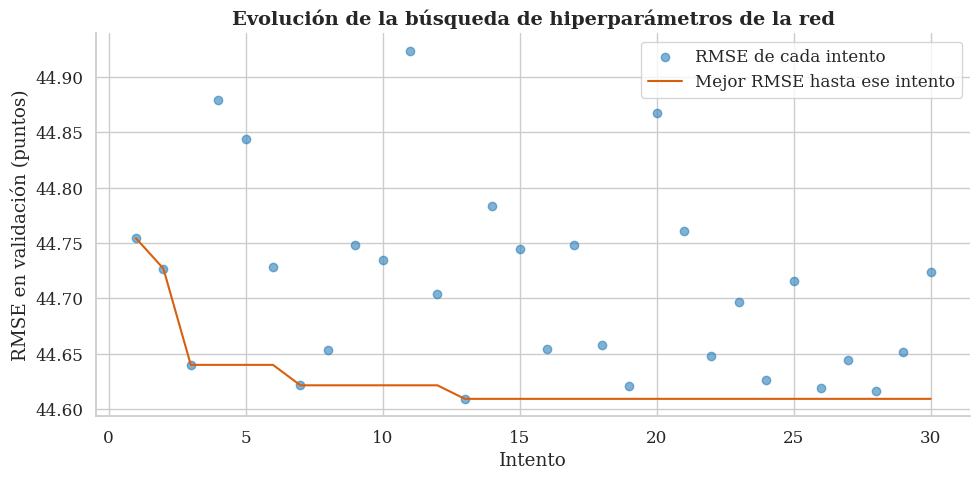

In [ ]:
intentos_red = estudio_red.trials_dataframe()
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(intentos_red["number"] + 1, intentos_red["value"], color=color_acento,
           alpha=0.6, label="RMSE de cada intento")
ax.plot(intentos_red["number"] + 1, intentos_red["value"].cummin(), color=color_secundario,
        label="Mejor RMSE hasta ese intento")
ax.set_xlabel("Intento")
ax.set_ylabel("RMSE en validación (puntos)")
ax.set_title("Evolución de la búsqueda de hiperparámetros de la red",
             fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
p = mejores_params_red
neuronas_opt = tuple(p["neuronas_primera_capa"] // 2**i for i in range(p["n_capas"]))

tf.keras.utils.set_random_seed(SEMILLA)
res_red_opt, historiales_opt = evaluar_red(
    X_red, y_eval, neuronas=neuronas_opt, dropout=p["dropout"],
    tasa_aprendizaje=p["tasa_aprendizaje"], tamano_lote=p["tamano_lote"],
)

fila_red_opt = pd.DataFrame({
    "R2": [res_red_opt["R2"].mean()],
    "RMSE": [res_red_opt["RMSE"].mean()],
    "RMSE desv.": [res_red_opt["RMSE"].std(ddof=0)],
    "MAE": [res_red_opt["MAE"].mean()],
    "RMSE entrenamiento": [res_red_opt["RMSE entrenamiento"].mean()],
    "Tiempo (s)": [res_red_opt["Tiempo (s)"].mean()],
}, index=["Red neuronal (optimizada)"])

comparacion_red = pd.concat([comparacion_hgb, fila_red, fila_red_opt]).round(3)

# Comparación fold por fold entre la red base y la optimizada (mismos folds)
red_por_fold = pd.DataFrame({
    "Red base": res_red["RMSE"].to_numpy(),
    "Red optimizada": res_red_opt["RMSE"].to_numpy(),
}, index=[f"Fold {i}" for i in range(1, 6)])
red_por_fold["Diferencia"] = red_por_fold["Red optimizada"] - red_por_fold["Red base"]

display(comparacion_red)
display(red_por_fold.round(3))

Fold 1: RMSE = 44.61 (35 épocas, 43 s)
Fold 2: RMSE = 44.43 (32 épocas, 39 s)
Fold 3: RMSE = 44.80 (27 épocas, 34 s)
Fold 4: RMSE = 44.63 (28 épocas, 34 s)
Fold 5: RMSE = 44.84 (33 épocas, 41 s)


,R2,RMSE,RMSE desv.,MAE,RMSE entrenamiento,Tiempo (s)
HGB por defecto,0.346,44.494,0.143,35.932,44.005,3.751
HGB optimizado,0.349,44.399,0.138,35.815,43.616,12.840
Red neuronal (base),0.339,44.733,0.165,36.163,44.314,18.774
Red neuronal (optimizada),0.341,44.664,0.147,36.090,43.990,38.087


,Red base,Red optimizada,Diferencia
Fold 1,44.650,44.609,-0.041
Fold 2,44.457,44.435,-0.022
Fold 3,44.898,44.805,-0.093
Fold 4,44.770,44.627,-0.143
Fold 5,44.888,44.842,-0.046


**Resultados de la optimización de la red:**

- **Mejores hiperparámetros:** 2 capas ocultas de 256 y 128 neuronas, dropout de 0.22, tasa de aprendizaje de 0.0004 y lotes de 256 estudiantes. La configuración se parece a la red base (2 capas y dropout cercano a 0.2), pero con más neuronas, una tasa de aprendizaje más baja y lotes más pequeños, lo que permite que la red aprenda con pasos más finos.
- **Evolución de la búsqueda:** el mejor resultado aparece en el intento 13 y no mejora en los 17 siguientes. Como con HistGradientBoosting, la red es poco sensible a sus hiperparámetros.
- **Mejora:** con los 5 folds, el RMSE baja de 44.73 a 44.66 y el R² sube de 0.339 a 0.341. La red optimizada tiene menor error que la base en los 5 folds, así que la mejora es pequeña pero consistente.
- **Comparación con el mejor modelo de machine learning:** HistGradientBoosting optimizado sigue siendo mejor (RMSE 44.40) y tiene menor error en los 5 folds, por entre 0.20 y 0.34 puntos. Además, la red tarda unas 3 veces más en entrenar (38 s frente a 13 s por fold).

**Interpretación:** la red neuronal alcanza resultados comparables con los mejores modelos de machine learning (supera a la regresión lineal y a Random Forest), pero no supera a HistGradientBoosting. Es un resultado habitual en datos tabulares: los modelos de ensamble de árboles suelen igualar o superar a las redes neuronales en este tipo de datos. Además, todos los modelos quedan cerca de 44–45 puntos, lo que confirma que el límite está en la información de las variables y no en el tipo de modelo.

## Paso 9. Evaluación final en el conjunto de prueba

El conjunto de prueba (20%, unos 114 mil estudiantes) se apartó en el paso 3 y no se usó en ninguna decisión. Ahora se usa **una sola vez** para medir qué tan bien predicen los modelos finales con estudiantes nuevos.

**Modelos finales**, entrenados con todo el conjunto de entrenamiento (455 mil estudiantes) y las 18 variables seleccionadas:
- **Regresión Lineal:** la línea base.
- **HistGradientBoosting optimizado:** el mejor modelo de machine learning.
- **Red neuronal optimizada:** el modelo de deep learning.

**Métricas de regresión:**
- **MSE** (error cuadrático medio): promedio de los errores al cuadrado. Penaliza más los errores grandes. Está en puntos al cuadrado, así que es difícil de interpretar directamente.
- **RMSE** (raíz del MSE): el error típico, en puntos.
- **MAE** (error absoluto medio): el error promedio, en puntos. Es menos sensible a los errores grandes que el RMSE.
- **R²:** qué parte de las diferencias de puntaje entre estudiantes explica el modelo (de 0 a 1).

**Gráficos del mejor modelo:** puntaje predicho frente al real, y la distribución del error de predicción de cada estudiante (puntaje real menos predicho). Un error positivo significa que el modelo predijo menos de lo que el estudiante sacó, y uno negativo, que predijo más. Estos gráficos muestran si el modelo se equivoca más con algunos estudiantes que con otros.

In [ ]:
X_tr_final = X_train[cols_seleccionadas]
X_te_final = X_test[cols_seleccionadas]

# Línea base
lineal_final = LinearRegression().fit(X_tr_final, y_train)

# HistGradientBoosting con los hiperparámetros de Optuna
hgb_final = HistGradientBoostingRegressor(**mejores_params, max_iter=500,
                                          early_stopping=True, random_state=SEMILLA)
hgb_final.fit(X_tr_final, y_train)

# Red neuronal con los hiperparámetros de Optuna
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)
media_y, desv_y = y_train.mean(), y_train.std()
red_final = crear_red(len(cols_seleccionadas), neuronas_opt,
                      mejores_params_red["dropout"], mejores_params_red["tasa_aprendizaje"])
parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                          restore_best_weights=True)
red_final.fit(X_tr_final.to_numpy("float32"), ((y_train - media_y) / desv_y).to_numpy(),
              validation_split=0.1, epochs=100, batch_size=mejores_params_red["tamano_lote"],
              callbacks=[parada], verbose=0)

# Predicciones en el test (la red se vuelve a convertir a puntos)
predicciones = pd.DataFrame({
    "Regresión Lineal": lineal_final.predict(X_te_final),
    "HGB optimizado": hgb_final.predict(X_te_final),
    "Red neuronal optimizada": red_final.predict(X_te_final.to_numpy("float32"),
                                                 batch_size=4096, verbose=0).ravel() * desv_y + media_y,
}, index=X_test.index)

# Puntaje real, predicciones y grupos de cada estudiante del test (para el paso 10)
resultados_test = grupos_test.join(predicciones).assign(puntaje_real=y_test)
resultados_test.head()

,cole_depto_ubicacion,cole_naturaleza,cole_area_ubicacion,periodo,Regresión Lineal,HGB optimizado,Red neuronal optimizada,puntaje_real
296290,CORDOBA,OFICIAL,URBANA,20252,273.013695,277.277467,277.422306,262
112969,CORDOBA,OFICIAL,URBANA,20252,250.841985,240.058921,250.429626,177
296478,BOGOTÁ,OFICIAL,URBANA,20252,251.463817,273.414196,266.923550,278
171054,ANTIOQUIA,OFICIAL,URBANA,20252,240.211854,244.174481,244.261471,253
65990,VALLE,NO OFICIAL,RURAL,20252,244.817814,251.232002,247.773468,283


In [ ]:
tabla_test = pd.DataFrame({
    modelo: {
        "MSE": mean_squared_error(y_test, predicciones[modelo]),
        "RMSE": mean_squared_error(y_test, predicciones[modelo]) ** 0.5,
        "MAE": mean_absolute_error(y_test, predicciones[modelo]),
        "R2": r2_score(y_test, predicciones[modelo]),
    }
    for modelo in predicciones
}).T

tabla_test.round(3)

,MSE,RMSE,MAE,R2
Regresión Lineal,2116.138,46.001,37.264,0.299
HGB optimizado,1951.839,44.180,35.650,0.353
Red neuronal optimizada,1967.331,44.355,35.790,0.348


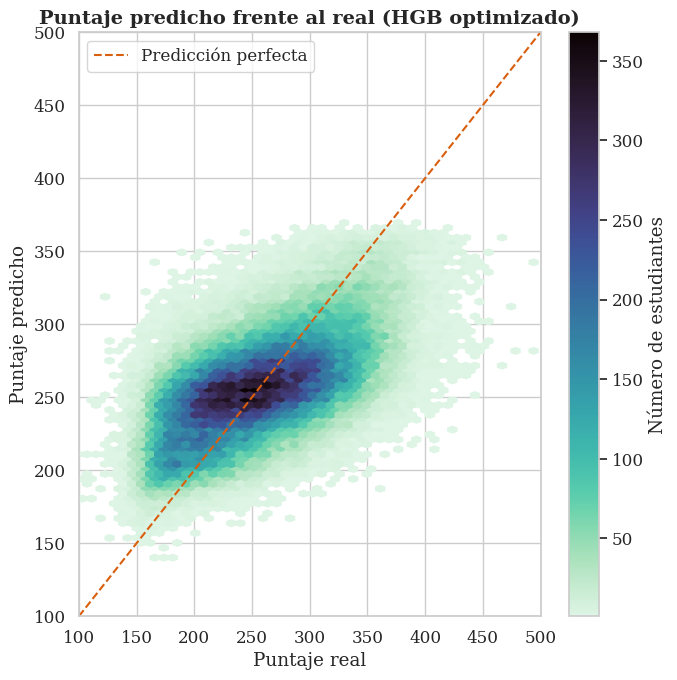

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(resultados_test["puntaje_real"], resultados_test["HGB optimizado"],
               gridsize=60, cmap="mako_r", mincnt=1)
limites = [100, 500]
ax.plot(limites, limites, color=color_secundario, linestyle="--", label="Predicción perfecta")
ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_xlabel("Puntaje real")
ax.set_ylabel("Puntaje predicho")
ax.set_title("Puntaje predicho frente al real (HGB optimizado)",
             fontsize=14, fontweight="bold")
fig.colorbar(hb, ax=ax, label="Número de estudiantes")
ax.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.show()

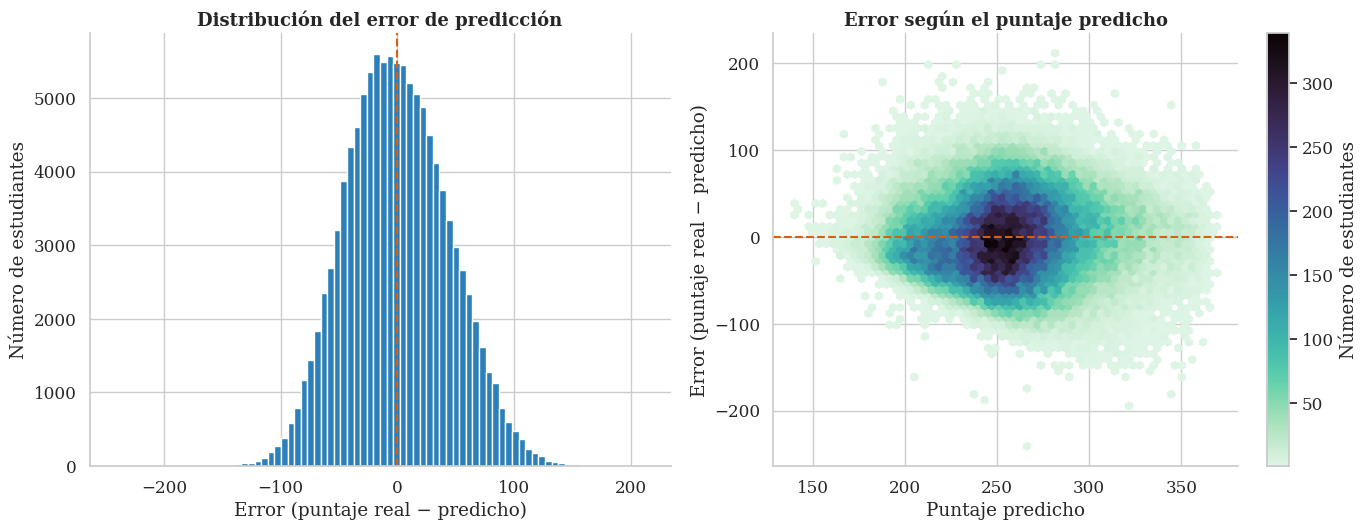

Error promedio: 0.06
Mitad de los estudiantes con error menor a: 30.8 puntos
% de estudiantes con error menor a 30 puntos: 48.9%


In [ ]:
# Error de predicción de cada estudiante (positivo: el modelo predijo de menos)
errores = resultados_test["puntaje_real"] - resultados_test["HGB optimizado"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Distribución del error
axes[0].hist(errores, bins=80, color=color_acento)
axes[0].axvline(0, color=color_secundario, linestyle="--")
axes[0].set_xlabel("Error (puntaje real − predicho)")
axes[0].set_ylabel("Número de estudiantes")
axes[0].set_title("Distribución del error de predicción", fontsize=13, fontweight="bold")

# Error según el puntaje predicho
hb = axes[1].hexbin(resultados_test["HGB optimizado"], errores,
                    gridsize=60, cmap="mako_r", mincnt=1)
axes[1].axhline(0, color=color_secundario, linestyle="--")
axes[1].set_xlabel("Puntaje predicho")
axes[1].set_ylabel("Error (puntaje real − predicho)")
axes[1].set_title("Error según el puntaje predicho", fontsize=13, fontweight="bold")
fig.colorbar(hb, ax=axes[1], label="Número de estudiantes")

sns.despine()
plt.tight_layout()
plt.show()

print(f"Error promedio: {errores.mean():.2f}")
print(f"Mitad de los estudiantes con error menor a: {errores.abs().median():.1f} puntos")
print(f"% de estudiantes con error menor a 30 puntos: {(errores.abs() < 30).mean():.1%}")

**Resultados en el conjunto de prueba:**

- **HistGradientBoosting optimizado es el mejor modelo:** RMSE de 44.18, MAE de 35.65 y R² de 0.353. Frente a la línea base (regresión lineal: RMSE 46.00, R² 0.299). La red neuronal queda en segundo lugar (RMSE 44.36, R² 0.348), a solo 0.18 puntos de HistGradientBoosting.
- **El orden de los modelos es el mismo que en la validación cruzada**, así que la elección del modelo se confirma con estudiantes nuevos.
- **El modelo generaliza bien:** el RMSE en el test (44.18) es casi igual al obtenido en validación con 364 mil estudiantes en la curva de aprendizaje (44.20). Las decisiones tomadas con la validación (modelo, variables e hiperparámetros) funcionan igual con datos que no se usaron para tomarlas.

**Puntaje predicho frente al real:** la nube de puntos sigue la diagonal, pero es más plana que ella: el modelo predice entre unos 150 y 370 puntos, mientras que los puntajes reales van de unos 100 a 480. Es decir, subestima a los estudiantes con puntajes altos y sobreestima a los de puntajes bajos. Como las variables explican solo alrededor de un tercio del puntaje, el modelo tiende a predecir valores cercanos al promedio, y no logra distinguir a los estudiantes con resultados extremos.

**Error de predicción:**
- La distribución del error tiene forma de campana, centrada en 0 y simétrica: el modelo no tiende a predecir de más ni de menos.
- El error es parecido en todo el rango de puntajes predichos: el modelo se equivoca más o menos igual con todos los niveles de predicción.
- La mitad de los estudiantes tiene un error menor a 31 puntos, y el 49% tiene un error menor a 30 puntos.